In [ ]:
# Uninstall potentially conflicting packages, including gower
!pip uninstall -y numpy scikit-learn scikit-learn-extra pandas gower

# Install specific versions, starting with numpy
!pip install numpy==1.26.4
!pip install scikit-learn==1.4.2
!pip install scikit-learn-extra==0.3.0
!pip install pandas==2.2.2 # Install pandas after numpy

# Install gower as it was also part of the original code
!pip install gower


# Force runtime restart to fix numpy dtype mismatch
import os
os.kill(os.getpid(), 9)


Found existing installation: numpy 2.0.2
Uninstalling numpy-2.0.2:
  Successfully uninstalled numpy-2.0.2
Found existing installation: scikit-learn 1.6.1
Uninstalling scikit-learn-1.6.1:
  Successfully uninstalled scikit-learn-1.6.1
Found existing installation: pandas 2.2.2
Uninstalling pandas-2.2.2:
  Successfully uninstalled pandas-2.2.2
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.0/18.0 MB 55.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dask-cudf-cu12 25.10.0 requires pandas<2.4.0dev0,>=2.0, which is not installed.
statsmodels 0.14.6 requires pandas!=2.1.0,>=1.4, which is not installed.
tensorflow-decision-forests 1.12.0 requires pandas, which is not installed.
bokeh 3.7.3 requires pandas>=1.2, which is not installed.
prophet 1.2.1 requires pandas>=1.0.4,

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.2/12.2 MB 124.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
pysal 25.7 requires pandas>=1.4, which is not installed.
segregation 2.5.3 requires pandas, which is not installed.
mapclassify 2.10.0 requires pandas>=2.1, which is not installed.
spopt 0.7.0 requires pandas>=2.1.0, which is not installed.
fastai 2.8.6 requires pandas, which is not installed.
shap 0.50.0 requires pandas, which is not installed.
esda 2.8.0 requires pandas>=2.1, which is not installed.
sklearn-pandas 2.2.0 requires pandas>=1.1.4, which is not installed.
tsfresh 0.21.1 requires pandas>=0.25.0, which is not installed.
spreg 1.8.4 requires pandas, which is not installed.
spaghetti 1.7.6 requires pandas!=1.5.0,>=1.4, which is not installed.
libpysal 4.13.0 requires pandas>=1.4, which is not installed.
mlxtend 0.23.4 require

In [ ]:

# import the libraries
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from pandas.tseries.offsets import DateOffset

from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_val_score, GridSearchCV, StratifiedKFold
from sklearn_extra.cluster import KMedoids
from sklearn.metrics import silhouette_score, pairwise_distances, davies_bouldin_score, adjusted_rand_score, normalized_mutual_info_score
from sklearn.decomposition import PCA
import gower
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D
from google.colab import files
from google.colab import drive
from sklearn.svm import SVC
from sklearn.tree import plot_tree
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import StratifiedKFold, train_test_split, cross_validate
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sentence_transformers import SentenceTransformer
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay

from sklearn.model_selection import StratifiedKFold, cross_val_predict


In [ ]:

drive.mount('/content/drive')

df_model_path = '/content/drive/MyDrive/למידת מכונה/df_model.pkl'
df_model = pd.read_pickle(df_model_path)

df_path = '/content/drive/MyDrive/למידת מכונה/df.pkl'
df = pd.read_pickle(df_path)

y = df['sentiment']
print(df_model.shape)
print(df.shape)

X = df_model  # full feature table

df.head()

Mounted at /content/drive
(39473, 324)
(39473, 64)


,id,text,sentiment,type,post_datetime,timezone,post_likes,posts_retweets,embedded_content_url,username,...,hashtag_count,followers_scaled,posts_retweets_scaled,previous_posts_count_scaled,years_on_platform_scaled,hashtag_count_scaled,pos_score,neg_score,pos_score_scaled,neg_score_scaled
0,2f2c6353-32b9-4432-b285-39ac9102bb03,i feel selfish when i send a chapter because i...,negative,post,2025-08-21 20:35:00,AEST,63.0,31.0,https://assets.storage.net/1dacdb5c-dbae-4982-...,@user6423,...,0,0.003024,0.001859,0.212077,0.428571,0.000000,0.0,17.0,0.000000,0.062963
1,d61d3af4-e568-4a9d-8f16-b6ce98da2b60,i couldnt help feeling like this scene was goi...,positive,retweet,2021-10-13 10:04:00,EET,53.0,2.0,NaN,@brian_han,...,0,0.000265,0.000120,0.000000,0.190476,0.000000,39.0,0.0,0.236364,0.000000
2,08661df4-3ff2-4092-8c72-98734c7a7aea,i liked it for its free feeling and i really l...,positive,reply,2022-03-08 09:21:00,GMT,51.0,4.0,NaN,@thomasz5t,...,0,0.000389,0.000240,0.132548,0.380952,0.000000,93.0,0.0,0.563636,0.000000
3,538a4160-18f0-4344-a0d0-a421224ace84,i retreat ended i woke up feeling extremely ag...,negative,post,2023-02-04 20:32:00,MSK,28.0,4.0,https://assets.storage.net/9d0a975e-8f6b-49a3-...,@door2739,...,0,0.000108,0.000240,0.000000,0.142857,0.000000,0.0,11.0,0.000000,0.040741
4,66ce15b4-5070-4430-8c08-4bead309acb2,i have been thinking hard about all that feeli...,negative,post,2025-11-13 15:30:00,PST,51.0,14.0,https://assets.storage.net/a218a3d0-b0e9-4819-...,@56emrl3f,...,3,0.000978,0.000839,0.072165,0.333333,0.333333,0.0,20.0,0.000000,0.074074


LogisticRegression Test - K Folds


In [ ]:
# Define the CV strategy
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Define your model pipeline
pipe = Pipeline([
    ('pre', 'passthrough'),   # use your preprocessor here; or 'passthrough'
    ('clf', LogisticRegression(max_iter=1000, class_weight='balanced'))
])

# Run 5-fold CV with AUC scoring
auc_scores = cross_val_score(pipe, X, y, scoring='roc_auc', cv=cv, n_jobs=-1)

# Show results
print("AUC per fold:", np.round(auc_scores, 3))
print("Average AUC (5-fold CV):", np.round(auc_scores.mean(), 3))


AUC per fold: [0.946 0.943 0.943 0.943 0.947]
Average AUC (5-fold CV): 0.944


## Decision Trees

Checking the Optimal Depth

In [ ]:
depths = [3, 5, 7, 10, 15, 20, 25, 30, 35, 40, 45, 50, 55, 60, 65, 70]
avg_aucs = []

for d in depths:
    model = DecisionTreeClassifier(max_depth=d, class_weight='balanced', random_state=42)
    pipe = Pipeline([
        ('pre', 'passthrough'),  # or your real preprocessor if you used one
        ('clf', model)
    ])
    auc_scores = cross_val_score(pipe, X, y, scoring='roc_auc', cv=cv, n_jobs=-1)
    avg_auc = auc_scores.mean()
    avg_aucs.append(avg_auc)
    print(f"Depth {d} → AUC: {avg_auc:.3f}")

plt.figure(figsize=(8, 5))
plt.plot(depths, avg_aucs, marker='o', linestyle='-')
plt.title("Decision Tree AUC vs. Max Depth")
plt.xlabel("Max Depth")
plt.ylabel("Average AUC (5-fold CV)")
plt.grid(True)
plt.xticks(depths)
plt.show()


NameError: name 'DecisionTreeClassifier' is not defined

Grid Search

In [ ]:

pipe = Pipeline([
    ('pre', 'passthrough'),
    ('clf', DecisionTreeClassifier(random_state=42))
])

#the grid
param_grid = {
    'clf__max_depth': [7, 8],
    'clf__min_samples_split': [2, 10],
    'clf__min_samples_leaf': [1, 5],
    'clf__criterion': ['gini', 'entropy'],
    'clf__class_weight': [None, 'balanced']
}

#K-Fold
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

#Grid Search
grid = GridSearchCV(pipe,
                    param_grid=param_grid,
                    scoring='roc_auc',
                    cv=cv,
                    n_jobs=-1,
                    verbose=2, return_train_score=True)

grid.fit(X, y)

#resultes
print("\nBest AUC:", round(grid.best_score_, 3))
print("Best parameters:", grid.best_params_)

#Show all combinations with scores
results_df = pd.DataFrame(grid.cv_results_)
results_df = results_df[['params', 'mean_test_score', 'std_test_score']]
results_df = results_df.sort_values(by='mean_test_score', ascending=False)

print("\nTop configurations:")
print(results_df.head(10).to_string(index=False))

results = pd.DataFrame(grid.cv_results_)

# Show only relevant columns
results_summary = results[['params', 'mean_train_score', 'mean_test_score', 'rank_test_score']]
results_summary = results_summary.sort_values(by='mean_test_score', ascending=False)

print(results_summary.head(10))

The Best Tree

In [ ]:
# Create and fit the tree
best_tree = DecisionTreeClassifier(
    max_depth=7,
    min_samples_leaf=5,
    min_samples_split=2,
    criterion='gini',
    class_weight=None,
    random_state=42
)

best_tree.fit(X, y)

DecisionTreeClassifier(max_depth=7, min_samples_leaf=5, random_state=42)

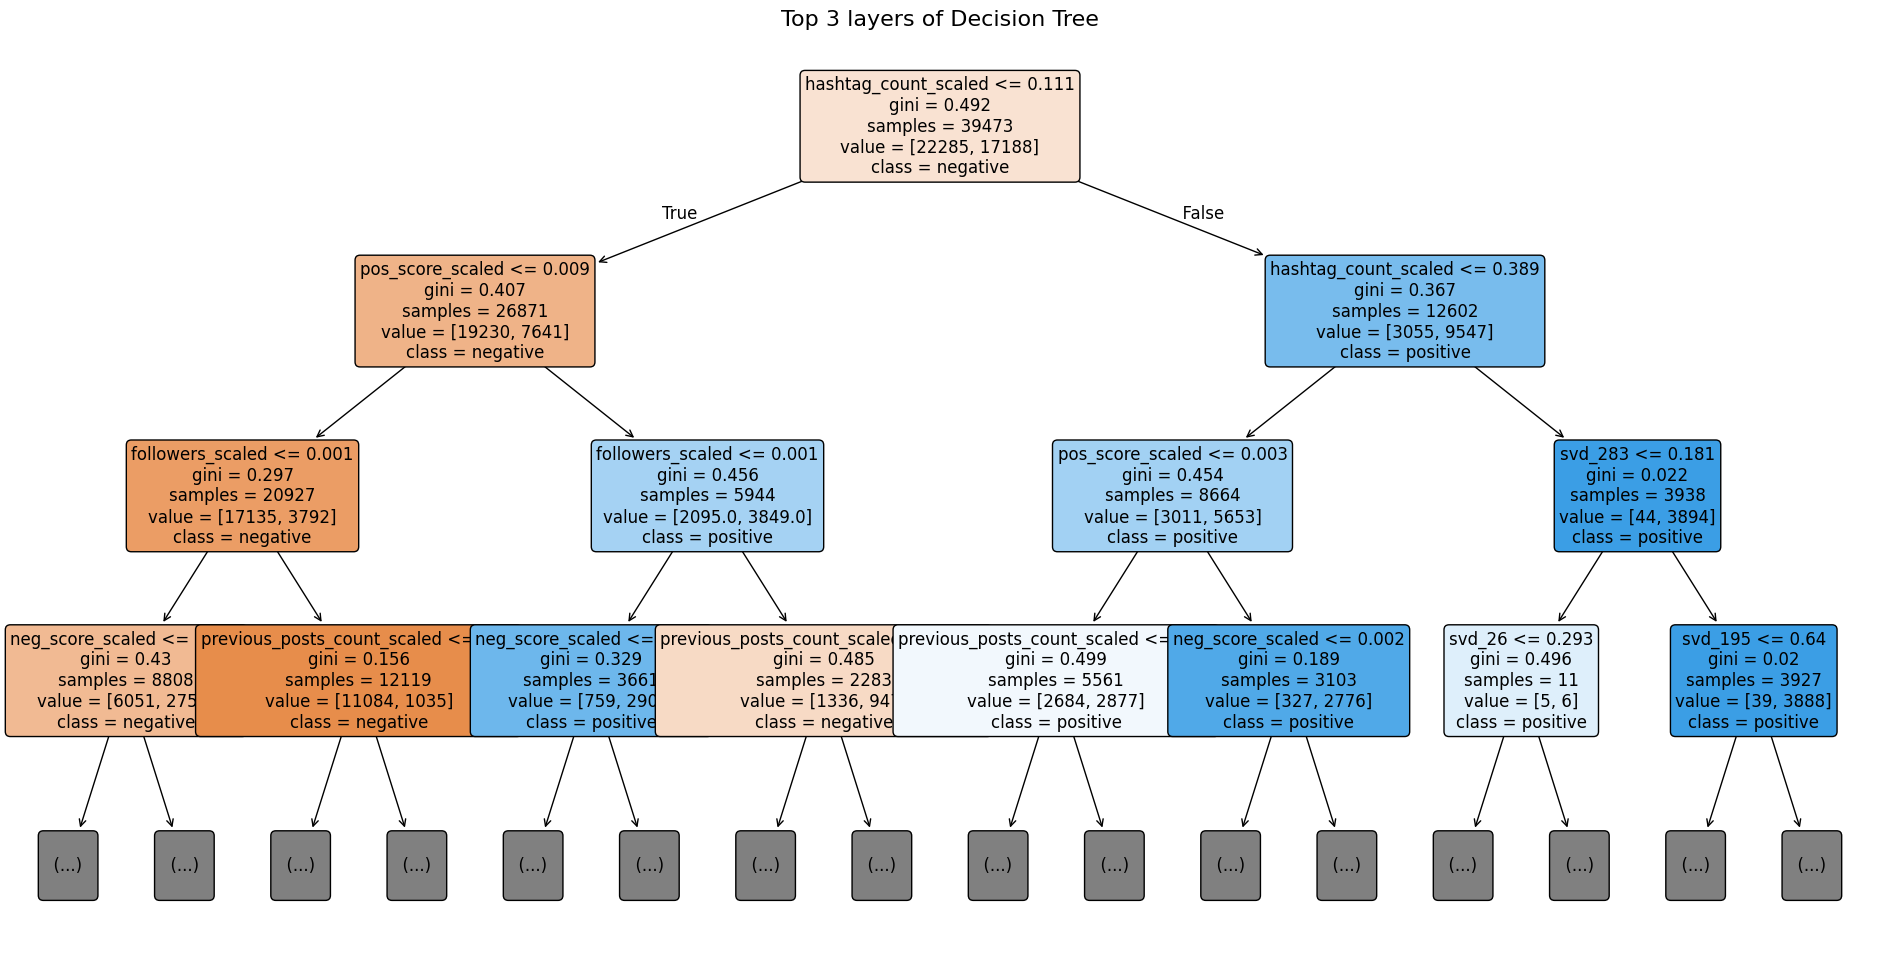

In [ ]:

#Top 3 layers of Decision Tree

plt.figure(figsize=(24, 12))
plot_tree(best_tree,
          feature_names=X.columns,
          class_names=['negative', 'positive'],
          max_depth=3,               # only top layers
          filled=True,
          rounded=True,
          fontsize=12)
plt.title("Top 3 layers of Decision Tree", fontsize=16)
plt.show()

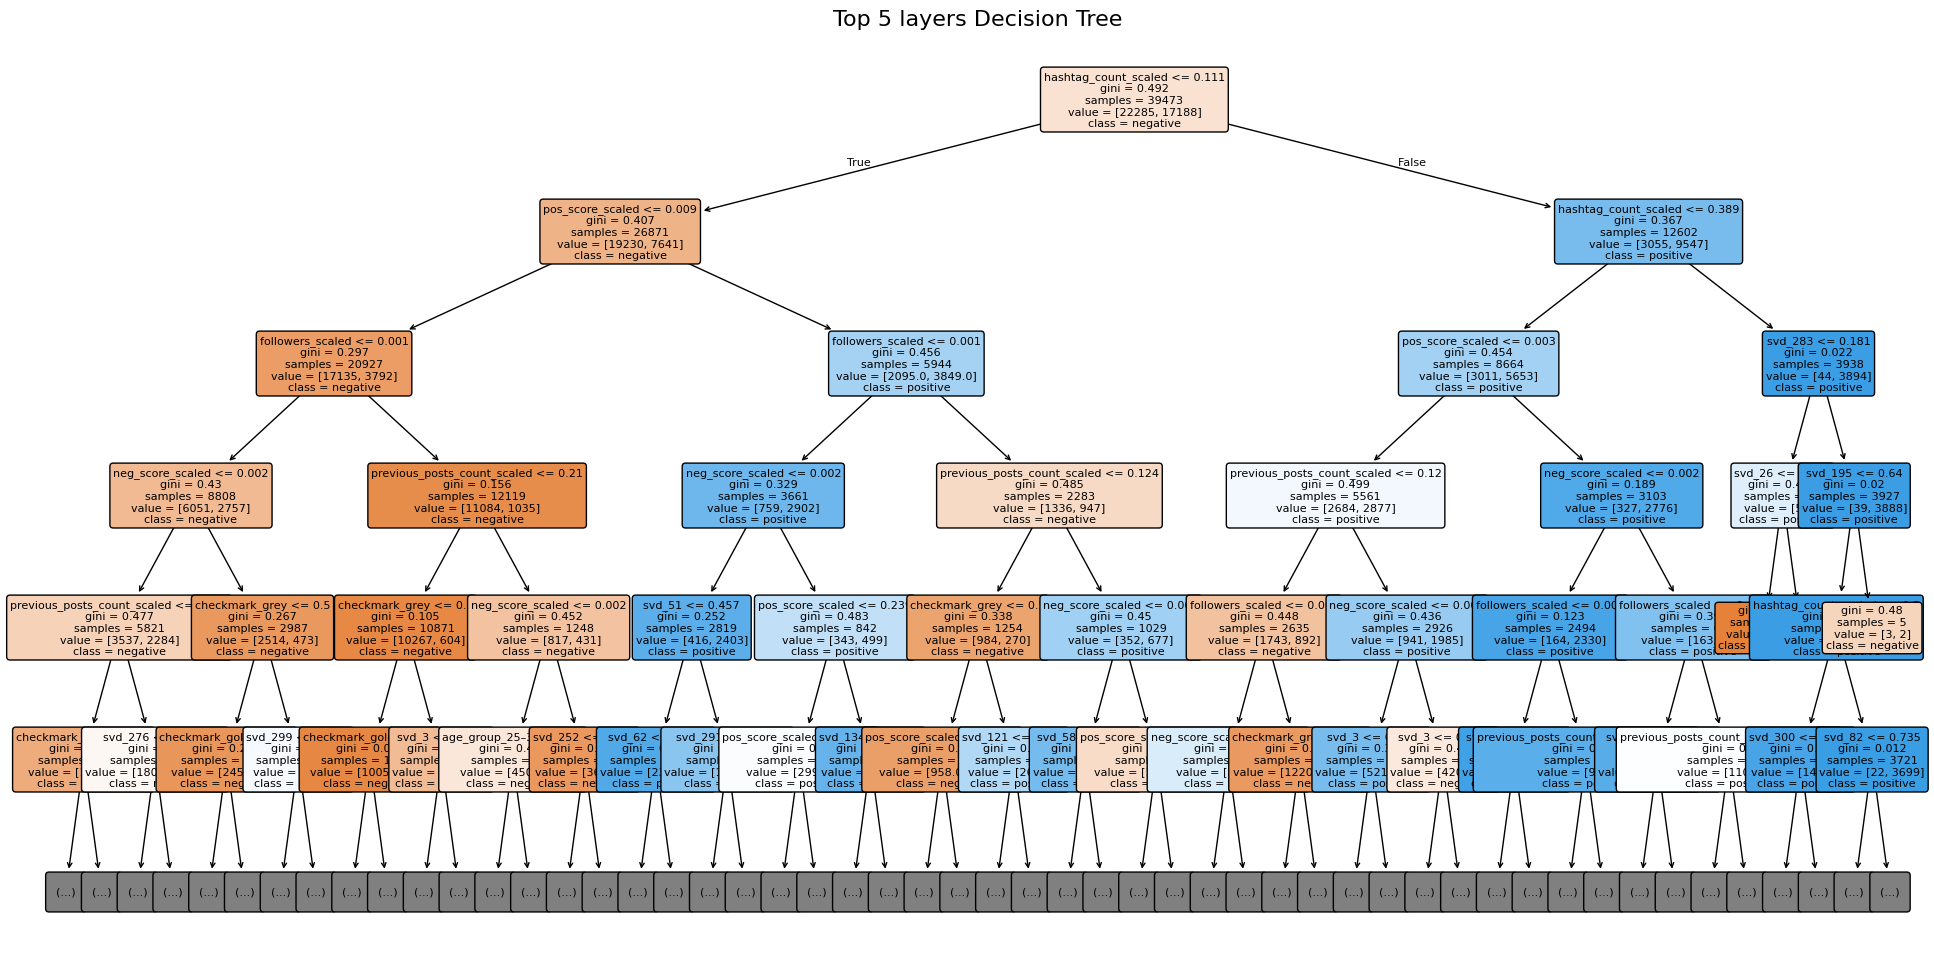

In [ ]:
#Top 3 layers of Decision Tree

plt.figure(figsize=(24, 12))
plot_tree(best_tree,
          feature_names=X.columns,
          class_names=['negative', 'positive'],
          max_depth=5,
          filled=True,
          rounded=True,
          fontsize=8)
plt.title("Top 5 layers Decision Tree", fontsize=16)
plt.show()

Features Importances

In [ ]:
importances = best_tree.feature_importances_
feat_importance_df = pd.DataFrame({'feature': X.columns,'importance': importances}).sort_values(by='importance', ascending=False)

print(feat_importance_df.head(10))


                         feature  importance
3           hashtag_count_scaled    0.406239
4               pos_score_scaled    0.244749
0               followers_scaled    0.106801
2    previous_posts_count_scaled    0.088278
5               neg_score_scaled    0.054445
9                 checkmark_grey    0.016473
8                 checkmark_gold    0.013790
26                         svd_3    0.009184
299                      svd_276    0.009108
272                      svd_249    0.006114


## SVM

In [ ]:

#grid search
param_grid = {'C': [0.01, 0.1, 1, 5, 10, 20]}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid = GridSearchCV(
    estimator=SVC(kernel='linear', class_weight='balanced'),
    param_grid=param_grid,
    scoring='roc_auc',
    cv=cv,
    n_jobs=-1,
    return_train_score=True
)

grid.fit(X, y)



GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=SVC(class_weight='balanced', kernel='linear'), n_jobs=-1,
             param_grid={'C': [0.01, 0.1, 1, 5, 10, 20]},
             return_train_score=True, scoring='roc_auc')

Results

In [ ]:
#best result
print("Best C:", grid.best_params_['C'])
print("Best mean AUC-ROC:", round(grid.best_score_, 4))

#all results
results_df = pd.DataFrame(grid.cv_results_)
results_df = results_df[['param_C','mean_train_score', 'mean_test_score', 'std_test_score']]
results_df = results_df.sort_values(by='param_C')

print("\nAll results:")
print(results_df.to_string(index=False))

#feature importance
best_svm = grid.best_estimator_
coefs = pd.Series(best_svm.coef_[0], index=X.columns)

print("\nTop 10 features by absolute weight:")
print(coefs.sort_values(key=abs, ascending=False).head(10))

#equation
bias = best_svm.intercept_[0]
print(f"\nEquation of the separating hyperplane: w·x + b = 0")
print(f"Intercept (b): {bias:.4f}")


#top 10 features in equation
top_features = coefs.sort_values(key=abs, ascending=False).head(10)

terms = [f"({w:.4f})·{f}" for f, w in top_features.items()]
equation = " + ".join(terms)
equation += f" + ({bias:.4f}) = 0"

print("\nLinear SVM Equation (Top 10 Features):")
print(equation)


Best C: 5
Best mean AUC-ROC: 0.9392

All results:
param_C  mean_train_score  mean_test_score  std_test_score
   0.01          0.895498         0.890655        0.005141
    0.1          0.938853         0.929817        0.003902
      1          0.951825         0.938831        0.003497
      5          0.954038         0.939200        0.003648
     10          0.954307         0.938960        0.003690
     20          0.954426         0.938754        0.003837

Top 10 features by absolute weight:
pos_score_scaled               9.127238
hashtag_count_scaled           6.935559
followers_scaled              -6.638632
neg_score_scaled              -5.512897
posts_retweets_scaled         -5.192167
svd_189                       -5.045012
svd_72                        -5.035298
previous_posts_count_scaled    3.842561
svd_74                         3.633900
svd_69                        -3.631476
dtype: float64

Equation of the separating hyperplane: w·x + b = 0
Intercept (b): 0.9597

Linear SVM

## MLP

Defult Model

In [ ]:

# Define model
mlp = MLPClassifier(max_iter=200, random_state=42)

# Cross-validation
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
results = cross_validate(
    mlp, X, y,
    cv=cv,
    scoring='roc_auc',
    return_train_score=True,
    n_jobs=-1
)

# Mean results
print("Mean Train AUC-ROC:", round(results['train_score'].mean(), 4))
print("Mean Validation AUC-ROC:", round(results['test_score'].mean(), 4))


Mean Train AUC-ROC: 0.963
Mean Validation AUC-ROC: 0.9451


Hidden Layer Sizes

Fitting 3 folds for each of 8 candidates, totalling 24 fits
Best parameters: {'hidden_layer_sizes': (100, 50)}
Best mean validation AUC-ROC: 0.9317

 Grid Search resultes:
param_hidden_layer_sizes  mean_train_score  mean_test_score
               (100, 50)          0.944297         0.931676
               (150, 75)          0.937224         0.925853
          (150, 100, 50)          0.935378         0.924463
                  (150,)          0.931169         0.922872
          (100, 100, 50)          0.935300         0.921762
              (200, 100)          0.930944         0.921692
                  (200,)          0.927798         0.919328
                  (100,)          0.912862         0.904381


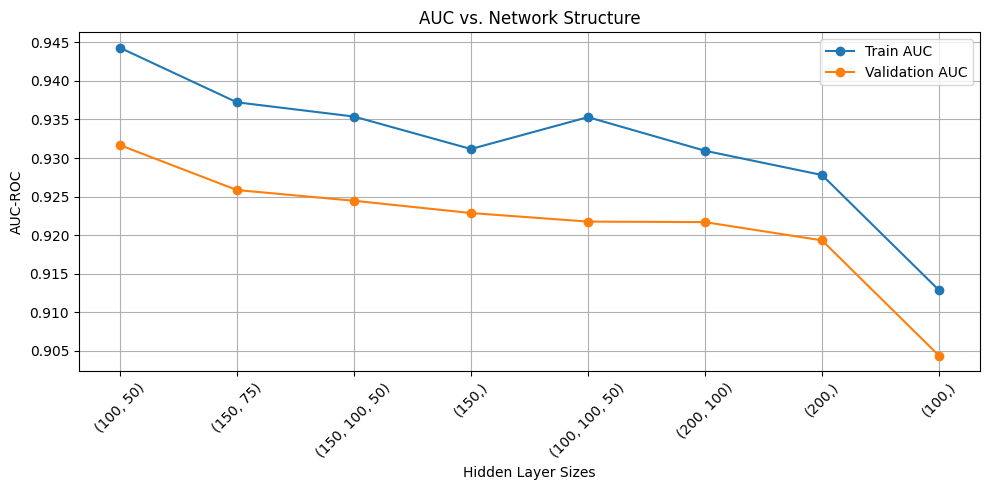

In [ ]:


param_grid = {
    'hidden_layer_sizes': [(100,), (150,), (200,),
                           (100, 50), (150, 75), (200, 100),
                           (100, 100, 50),(150, 100, 50)]
}

#mlp model
mlp = MLPClassifier(max_iter=100, early_stopping=True, n_iter_no_change=5, validation_fraction=0.1, random_state=42)
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

grid = GridSearchCV(
    estimator=mlp,
    param_grid=param_grid,
    scoring='roc_auc',
    cv=cv,
    return_train_score=True,
    n_jobs=-1,
    verbose=2
)

#train
grid.fit(X, y)

print("Best parameters:", grid.best_params_)
print("Best mean validation AUC-ROC:", round(grid.best_score_, 4))

#results
results_df = pd.DataFrame(grid.cv_results_)
summary = results_df[[
    'param_hidden_layer_sizes',
    'mean_train_score',
    'mean_test_score'
]].sort_values(by='mean_test_score', ascending=False)

print("\n Grid Search resultes:")
print(summary.to_string(index=False))

summary['structure'] = summary['param_hidden_layer_sizes'].apply(lambda x: str(x))

plt.figure(figsize=(10, 5))
plt.plot(summary['structure'], summary['mean_train_score'], marker='o', label='Train AUC')
plt.plot(summary['structure'], summary['mean_test_score'], marker='o', label='Validation AUC')
plt.xticks(rotation=45)
plt.xlabel("Hidden Layer Sizes")
plt.ylabel("AUC-ROC")
plt.title("AUC vs. Network Structure")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Hyper-Parameters Adjusting with GridSearch

In [ ]:
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
import pandas as pd

param_grid = {
    'hidden_layer_sizes': [(100,), (100, 50), (100, 75)],
    'learning_rate_init': [0.0005, 0.001, 0.005, 0.01],
    'batch_size': [32, 64],
    'activation': ['relu', 'tanh']
}

#mlp model
mlp = MLPClassifier(max_iter=300, early_stopping=True, n_iter_no_change=5, validation_fraction=0.1, random_state=42)
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

grid = GridSearchCV(
    estimator=mlp,
    param_grid=param_grid,
    scoring='roc_auc',
    cv=cv,
    return_train_score=True,
    n_jobs=-1,
    verbose=2
)

#train
grid.fit(X, y)

print("Best parameters:", grid.best_params_)
print("Best mean validation AUC-ROC:", round(grid.best_score_, 4))

#results
results_df = pd.DataFrame(grid.cv_results_)
summary = results_df[[
    'param_hidden_layer_sizes',
    'param_learning_rate_init',
    'param_batch_size',
    'param_activation',
    'mean_train_score',
    'mean_test_score'
]].sort_values(by='mean_test_score', ascending=False)

print("\n📊 Grid Search resultes")
print(summary.to_string(index=False))


Fitting 3 folds for each of 48 candidates, totalling 144 fits
Best parameters: {'activation': 'tanh', 'batch_size': 64, 'hidden_layer_sizes': (100, 75), 'learning_rate_init': 0.001}
Best mean validation AUC-ROC: 0.9465

📊 Grid Search resultes
param_hidden_layer_sizes param_learning_rate_init param_batch_size param_activation  mean_train_score  mean_test_score
               (100, 75)                    0.001               64             tanh          0.956036         0.946474
               (120, 60)                     0.01               32             relu          0.954843         0.945894
               (100, 50)                    0.001               32             relu          0.955638         0.945823
               (120, 60)                   0.0005               32             relu          0.954903         0.945232
               (100, 75)                    0.005               64             tanh          0.954517         0.944937
               (120, 60)                   

# The best model

In [ ]:
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
import pandas as pd

param_grid = {
    'hidden_layer_sizes': [ (100, 75)],
    'learning_rate_init': [0.001],
    'batch_size': [64],
    'activation': ['tanh']
}

#mlp model
mlp = MLPClassifier(max_iter=300, early_stopping=True, n_iter_no_change=5, validation_fraction=0.1, random_state=42)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid = GridSearchCV(
    estimator=mlp,
    param_grid=param_grid,
    scoring='roc_auc',
    cv=cv,
    return_train_score=True,
    n_jobs=-1,
    verbose=2
)

#train
grid.fit(X, y)

print("Best parameters:", grid.best_params_)
print("Best mean validation AUC-ROC:", round(grid.best_score_, 4))

#results
results_df = pd.DataFrame(grid.cv_results_)
summary = results_df[[
    'param_hidden_layer_sizes',
    'param_learning_rate_init',
    'param_batch_size',
    'param_activation',
    'mean_train_score',
    'mean_test_score'
]].sort_values(by='mean_test_score', ascending=False)

print("\n📊 Grid Search resultes")
print(summary.to_string(index=False))


Fitting 5 folds for each of 1 candidates, totalling 5 fits
Best parameters: {'activation': 'tanh', 'batch_size': 64, 'hidden_layer_sizes': (100, 75), 'learning_rate_init': 0.001}
Best mean validation AUC-ROC: 0.9525

📊 Grid Search resultes
param_hidden_layer_sizes param_learning_rate_init param_batch_size param_activation  mean_train_score  mean_test_score
               (100, 75)                    0.001               64             tanh          0.957555         0.952504


Mean Train AUC-ROC: 0.9525
Validation AUC-ROC: 0.952


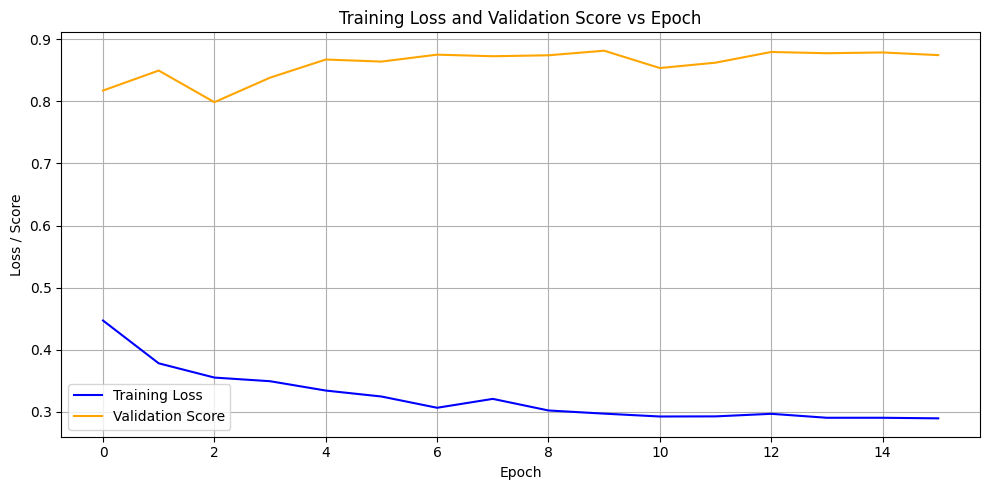

In [ ]:


# Define 3-fold CV
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Define the optimal model
model = MLPClassifier(
    hidden_layer_sizes=(100,75),
    activation='tanh',
    learning_rate_init=0.001,
    batch_size=64,
    max_iter=300,
    early_stopping=True,
    n_iter_no_change=5,
    validation_fraction=0.1,
    random_state=42
)

# Train AUC (mean over 5 folds)
train_auc_scores = cross_val_score(model, X, y, cv=cv, scoring='roc_auc', n_jobs=-1)
print("Mean Train AUC-ROC:", round(train_auc_scores.mean(), 4))

#Validation AUC using out-of-fold predictions
val_pred_proba = cross_val_predict(model, X, y, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]
val_auc = roc_auc_score(y, val_pred_proba)
print("Validation AUC-ROC:", round(val_auc, 4))

#Train once on all data to visualize loss + validation scores
model.fit(X, y)

#Plot: Training Loss and Validation Score
plt.figure(figsize=(10, 5))
plt.plot(model.loss_curve_, label='Training Loss', color='blue')

if hasattr(model, 'validation_scores_') and model.validation_scores_:
    plt.plot(model.validation_scores_, label='Validation Score', color='orange')

plt.xlabel("Epoch")
plt.ylabel("Loss / Score")
plt.title("Training Loss and Validation Score vs Epoch")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


 ROC Curve and Confusion Matrix

<ipython-input-9-38fb7623ccfa>:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  y_bin = y.replace({'negative': 0, 'positive': 1})
<ipython-input-9-38fb7623ccfa>:2: FutureWarning: The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that preserve the categories. To change the categories, use ser.cat.rename_categories instead.
  y_bin = y.replace({'negative': 0, 'positive': 1})


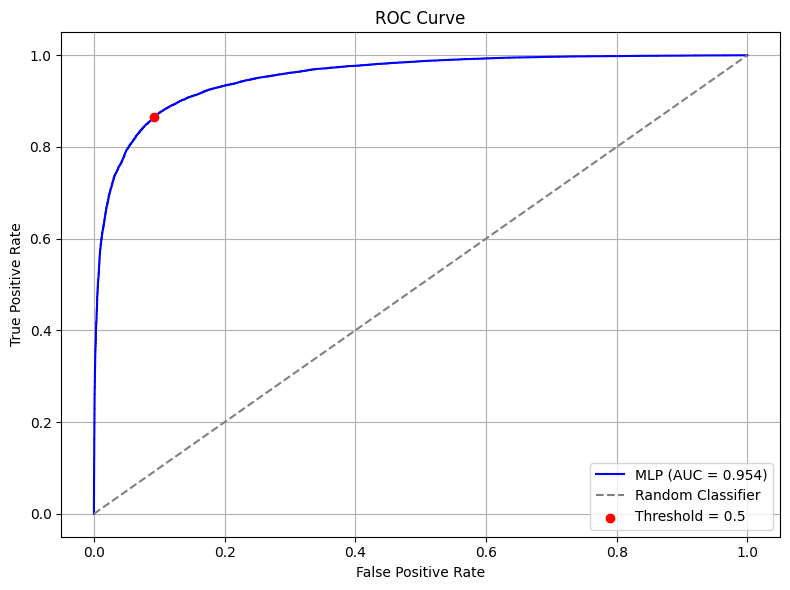

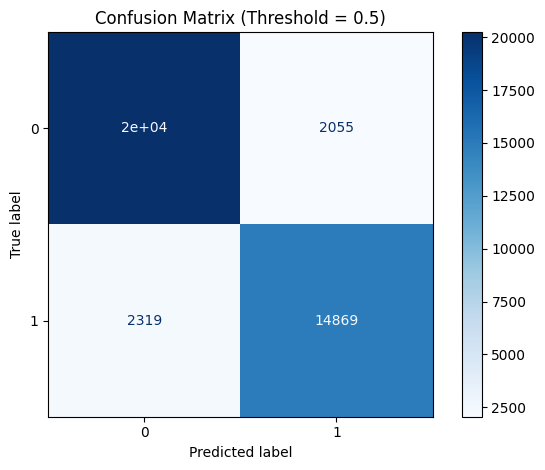

In [ ]:
#Convert string labels to binary
y_bin = y.replace({'negative': 0, 'positive': 1})

# Train model
model = MLPClassifier(
    hidden_layer_sizes=(100,75),
    activation='tanh',
    learning_rate_init=0.001,
    batch_size=64,
    max_iter=300,
    early_stopping=True,
    n_iter_no_change=5,
    validation_fraction=0.1,
    random_state=42
)
model.fit(X, y_bin)

# Predict probabilities
y_probs = model.predict_proba(X)[:, 1]

#ROC Curve
fpr, tpr, thresholds = roc_curve(y_bin, y_probs)
auc = roc_auc_score(y_bin, y_probs)

# Find threshold = 0.5
threshold = 0.5
threshold_idx = np.argmin(np.abs(thresholds - threshold))

# Plot ROC
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"MLP (AUC = {auc:.3f})", color='blue')
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier', color='gray')
plt.scatter(fpr[threshold_idx], tpr[threshold_idx], color='red', label=f'Threshold = 0.5', zorder=5)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# === Confusion Matrix ===
y_pred_thresh = (y_probs >= 0.5).astype(int)
cm = confusion_matrix(y_bin, y_pred_thresh)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap='Blues')
plt.title("Confusion Matrix (Threshold = 0.5)")
plt.grid(False)
plt.tight_layout()
plt.show()


### Improvements

Bert Model

In [ ]:
texts = df['text'].tolist()

# Load BERT model (lightweight)  ~384-dim embeddings
bert_model = SentenceTransformer('all-MiniLM-L6-v2')

# Encode texts into dense vectors
X_bert = bert_model.encode(texts, show_progress_bar=True)

/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/1234 [00:00<?, ?it/s]

In [ ]:
df_bert = pd.DataFrame(X_bert, columns=[f'bert_{i}' for i in range(X_bert.shape[1])])

selected_features = [
    'followers_scaled', 'posts_retweets_scaled', 'previous_posts_count_scaled', 'hashtag_count_scaled',
    'pos_score_scaled', 'neg_score_scaled',

    # Binary
    'has_profile_pic',

    # Categorical (one-hot encoded)
    'checkmark_blue', 'checkmark_gold', 'checkmark_grey', 'checkmark_none',
    'day_period_Early Morning', 'day_period_Morning', 'day_period_Midday', 'day_period_Afternoon',
    'day_period_Evening', 'day_period_Night',
    'age_group_<18', 'age_group_18–24', 'age_group_25–34', 'age_group_35–44',
    'age_group_45–54', 'age_group_55–64', 'age_group_65+'
]


df_model_improved = pd.concat([df[selected_features], df_bert], axis=1)

MLP with Bert features

Mean Train AUC-ROC: 0.9716
Validation AUC-ROC: 0.9706


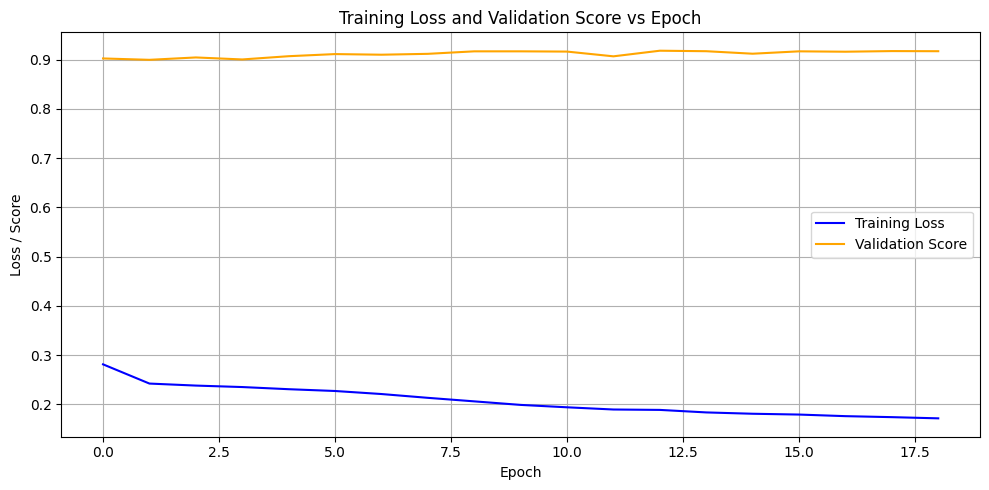

In [ ]:
# Define 3-fold CV
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Define the optimal model
model = MLPClassifier(
    hidden_layer_sizes=(100,75),
    activation='tanh',
    learning_rate_init=0.001,
    batch_size=64,
    max_iter=300,
    early_stopping=True,
    n_iter_no_change=5,
    validation_fraction=0.1,
    random_state=42
)

#Train AUC (mean over 5 folds)
train_auc_scores = cross_val_score(model, df_model_improved, y, cv=cv, scoring='roc_auc', n_jobs=-1)
print("Mean Train AUC-ROC:", round(train_auc_scores.mean(), 4))

#Validation AUC using out-of-fold predictions
val_pred_proba = cross_val_predict(model, df_model_improved, y, cv=cv, method='predict_proba', n_jobs=-1)[:, 1]
val_auc = roc_auc_score(y, val_pred_proba)
print("Validation AUC-ROC:", round(val_auc, 4))

# Train once on all data to visualize loss + validation scores
model.fit(df_model_improved, y)

#Plot: Training Loss and Validation Score
plt.figure(figsize=(10, 5))
plt.plot(model.loss_curve_, label='Training Loss', color='blue')

if hasattr(model, 'validation_scores_') and model.validation_scores_:
    plt.plot(model.validation_scores_, label='Validation Score', color='orange')

plt.xlabel("Epoch")
plt.ylabel("Loss / Score")
plt.title("Training Loss and Validation Score vs Epoch")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


<ipython-input-19-fff83860bb6d>:5: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  y_bin = y.replace({'negative': 0, 'positive': 1}).astype(int)
<ipython-input-19-fff83860bb6d>:5: FutureWarning: The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that preserve the categories. To change the categories, use ser.cat.rename_categories instead.
  y_bin = y.replace({'negative': 0, 'positive': 1}).astype(int)


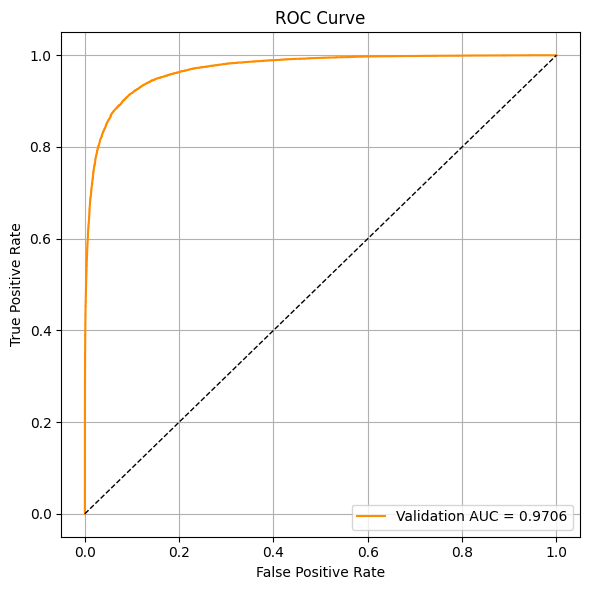

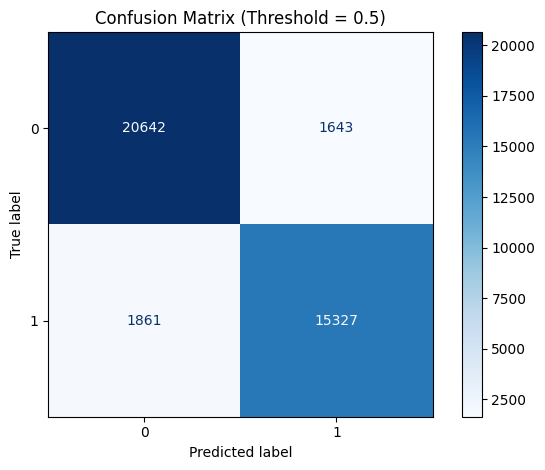

['mlp_classifier_model.pkl']

In [ ]:

from sklearn.metrics import roc_curve, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

X = df_model_improved.values
y_bin = y.replace({'negative': 0, 'positive': 1}).astype(int)
y_array = y_bin.values
#ROC Curve
fpr, tpr, thresholds = roc_curve(y_array, val_pred_proba)

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, label=f"Validation AUC = {val_auc:.4f}", color='darkorange')
plt.plot([0, 1], [0, 1], 'k--', lw=1)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.grid(True)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

#Confusion Matrix (threshold = 0.5)
val_pred_class = (val_pred_proba >= 0.5).astype(int)
cm = confusion_matrix(y_array, val_pred_class)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap='Blues')
plt.title("Confusion Matrix (Threshold = 0.5)")
plt.grid(False)
plt.tight_layout()
plt.show()

import joblib

# After training
joblib.dump(model, 'mlp_classifier_model.pkl')

Dropout Improvement

<ipython-input-14-7d119d73903c>:11: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  y_bin = y.replace({'negative': 0, 'positive': 1}).astype(int)
<ipython-input-14-7d119d73903c>:11: FutureWarning: The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that preserve the categories. To change the categories, use ser.cat.rename_categories instead.
  y_bin = y.replace({'negative': 0, 'positive': 1}).astype(int)


Epoch 1/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 7s 8ms/step - AUC: 0.9138 - loss: 0.3583 - val_AUC: 0.9602 - val_loss: 0.2531
Epoch 2/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - AUC: 0.9626 - loss: 0.2436 - val_AUC: 0.9619 - val_loss: 0.2438
Epoch 3/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - AUC: 0.9642 - loss: 0.2382 - val_AUC: 0.9618 - val_loss: 0.2470
Epoch 4/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - AUC: 0.9649 - loss: 0.2360 - val_AUC: 0.9631 - val_loss: 0.2424
Epoch 5/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - AUC: 0.9652 - loss: 0.2359 - val_AUC: 0.9622 - val_loss: 0.2454
Epoch 6/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - AUC: 0.9651 - loss: 0.2350 - val_AUC: 0.9634 - val_loss: 0.2423
Epoch 7/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - AUC: 0.9668 - loss: 0.2296 - val_AUC: 0.9630 - val_loss: 0.2427
Epoch 8/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - AUC: 0.9661 - loss: 0.2318 - val_AUC: 0.9629 - val_loss: 0.2427
Epoch 9/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - AU

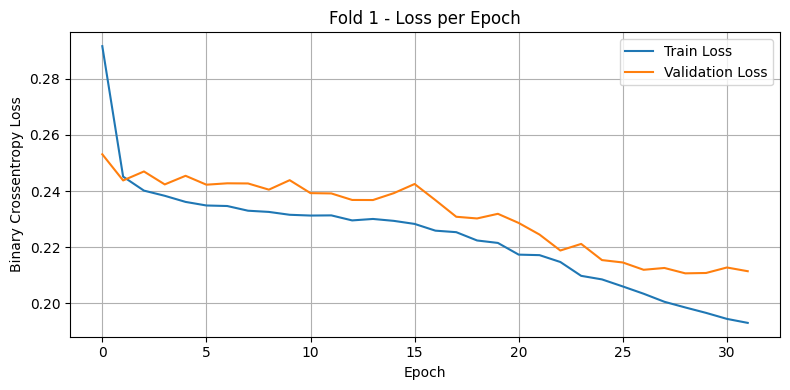

Epoch 1/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - AUC: 0.9073 - loss: 0.3638 - val_AUC: 0.9625 - val_loss: 0.2437
Epoch 2/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - AUC: 0.9613 - loss: 0.2474 - val_AUC: 0.9631 - val_loss: 0.2413
Epoch 3/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - AUC: 0.9642 - loss: 0.2387 - val_AUC: 0.9647 - val_loss: 0.2361
Epoch 4/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - AUC: 0.9635 - loss: 0.2405 - val_AUC: 0.9650 - val_loss: 0.2347
Epoch 5/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - AUC: 0.9640 - loss: 0.2379 - val_AUC: 0.9649 - val_loss: 0.2348
Epoch 6/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - AUC: 0.9637 - loss: 0.2402 - val_AUC: 0.9655 - val_loss: 0.2353
Epoch 7/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - AUC: 0.9653 - loss: 0.2338 - val_AUC: 0.9649 - val_loss: 0.2357
987/987 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
247/247 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


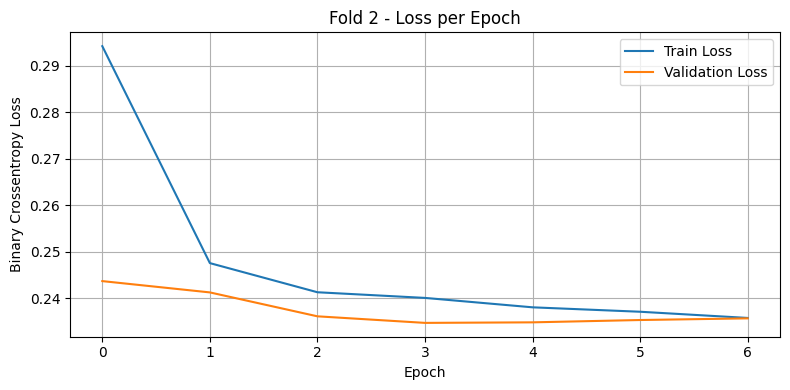

Epoch 1/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - AUC: 0.9065 - loss: 0.3637 - val_AUC: 0.9637 - val_loss: 0.2402
Epoch 2/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - AUC: 0.9619 - loss: 0.2467 - val_AUC: 0.9650 - val_loss: 0.2388
Epoch 3/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - AUC: 0.9627 - loss: 0.2430 - val_AUC: 0.9648 - val_loss: 0.2366
Epoch 4/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - AUC: 0.9638 - loss: 0.2379 - val_AUC: 0.9646 - val_loss: 0.2411
Epoch 5/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - AUC: 0.9659 - loss: 0.2325 - val_AUC: 0.9658 - val_loss: 0.2348
Epoch 6/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - AUC: 0.9651 - loss: 0.2348 - val_AUC: 0.9659 - val_loss: 0.2329
Epoch 7/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - AUC: 0.9651 - loss: 0.2356 - val_AUC: 0.9664 - val_loss: 0.2319
Epoch 8/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - AUC: 0.9659 - loss: 0.2315 - val_AUC: 0.9658 - val_loss: 0.2334
Epoch 9/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - AU

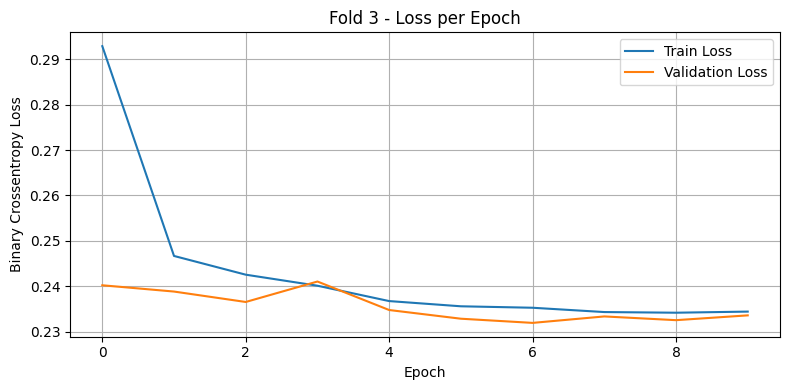

Epoch 1/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - AUC: 0.9151 - loss: 0.3571 - val_AUC: 0.9613 - val_loss: 0.2518
Epoch 2/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - AUC: 0.9614 - loss: 0.2472 - val_AUC: 0.9634 - val_loss: 0.2454
Epoch 3/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - AUC: 0.9619 - loss: 0.2446 - val_AUC: 0.9639 - val_loss: 0.2406
Epoch 4/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - AUC: 0.9650 - loss: 0.2343 - val_AUC: 0.9653 - val_loss: 0.2367
Epoch 5/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - AUC: 0.9660 - loss: 0.2303 - val_AUC: 0.9651 - val_loss: 0.2381
Epoch 6/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - AUC: 0.9650 - loss: 0.2355 - val_AUC: 0.9656 - val_loss: 0.2351
Epoch 7/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - AUC: 0.9661 - loss: 0.2314 - val_AUC: 0.9649 - val_loss: 0.2381
Epoch 8/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - AUC: 0.9688 - loss: 0.2206 - val_AUC: 0.9659 - val_loss: 0.2346
Epoch 9/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - AU

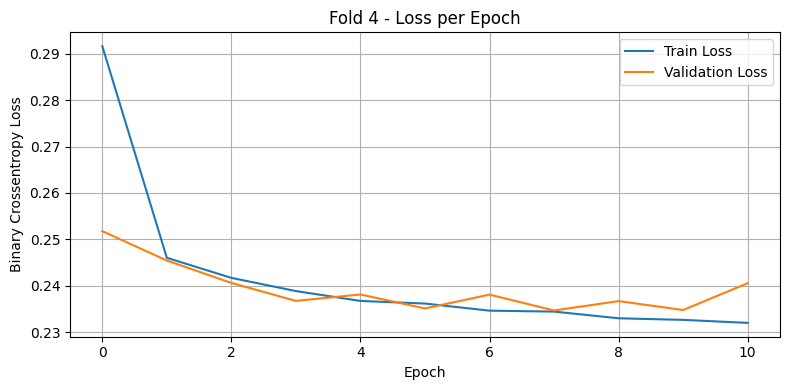

Epoch 1/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - AUC: 0.9111 - loss: 0.3585 - val_AUC: 0.9616 - val_loss: 0.2505
Epoch 2/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - AUC: 0.9610 - loss: 0.2483 - val_AUC: 0.9636 - val_loss: 0.2419
Epoch 3/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - AUC: 0.9633 - loss: 0.2408 - val_AUC: 0.9649 - val_loss: 0.2377
Epoch 4/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - AUC: 0.9648 - loss: 0.2360 - val_AUC: 0.9646 - val_loss: 0.2371
Epoch 5/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - AUC: 0.9654 - loss: 0.2346 - val_AUC: 0.9647 - val_loss: 0.2370
Epoch 6/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - AUC: 0.9654 - loss: 0.2338 - val_AUC: 0.9648 - val_loss: 0.2394
Epoch 7/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - AUC: 0.9653 - loss: 0.2336 - val_AUC: 0.9650 - val_loss: 0.2431
Epoch 8/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - AUC: 0.9661 - loss: 0.2307 - val_AUC: 0.9656 - val_loss: 0.2359
Epoch 9/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - AU

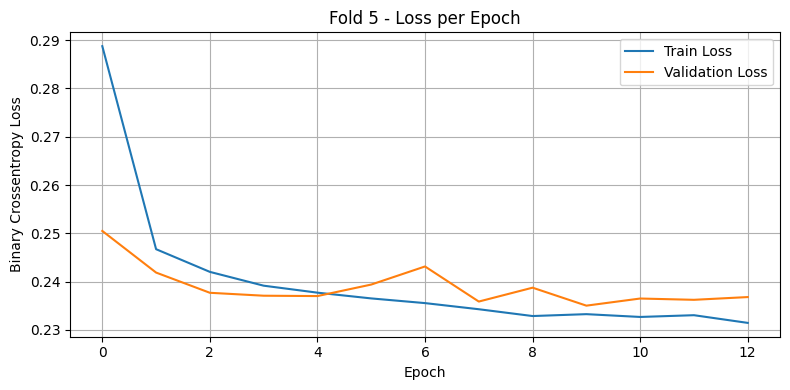

Train AUCs: [0.9795715809655904, 0.9670808024149958, 0.9680743182328106, 0.9682970208281668, 0.968185741263405]
Validation AUCs: [0.9716810481593686, 0.9650150628140426, 0.9664469470604182, 0.965907570931728, 0.965442388128138]
Mean Train AUC: 0.9702
Mean Validation AUC: 0.9669
Epoch 1/20
617/617 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - AUC: 0.9137 - loss: 0.3505
Epoch 2/20
617/617 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - AUC: 0.9636 - loss: 0.2404
Epoch 3/20
617/617 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - AUC: 0.9641 - loss: 0.2385
Epoch 4/20
617/617 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - AUC: 0.9636 - loss: 0.2395
Epoch 5/20
617/617 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - AUC: 0.9657 - loss: 0.2325
Epoch 6/20
617/617 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - AUC: 0.9665 - loss: 0.2301
Epoch 7/20
617/617 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - AUC: 0.9638 - loss: 0.2390
Epoch 8/20
617/617 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - AUC: 0.9655 - loss: 0.2330
Epoch 9/20
617/617 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - AUC: 0.9665 - loss:

In [ ]:
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
import numpy as np

X = df_model_improved.values
y_bin = y.replace({'negative': 0, 'positive': 1}).astype(int)
y_array = y_bin.values

def build_model():
    model = Sequential([
        Input(shape=(X.shape[1],)),
        Dense(100, activation='tanh'),
        Dense(75, activation='tanh'),
        Dropout(0.5),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer=Adam(learning_rate=0.001), loss='binary_crossentropy', metrics=['AUC'])
    return model

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
train_aucs, val_aucs = [], []

for fold_num, (train_idx, val_idx) in enumerate(cv.split(X, y_array), start=1):
    X_train, X_val = X[train_idx], X[val_idx]
    y_train, y_val = y_array[train_idx], y_array[val_idx]

    model = build_model()
    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=50,
        batch_size=64,
        verbose=1,
        callbacks=[EarlyStopping(patience=3, restore_best_weights=True)]
    )


    train_probs = model.predict(X_train).ravel()
    val_probs = model.predict(X_val).ravel()
    train_aucs.append(roc_auc_score(y_train, train_probs))
    val_aucs.append(roc_auc_score(y_val, val_probs))

    # 📊 Plot loss curves for this fold
    plt.figure(figsize=(8, 4))
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title(f"Fold {fold_num} - Loss per Epoch")
    plt.xlabel("Epoch")
    plt.ylabel("Binary Crossentropy Loss")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

print("Train AUCs:", train_aucs)
print("Validation AUCs:", val_aucs)
print("Mean Train AUC:", round(np.mean(train_aucs), 4))
print("Mean Validation AUC:", round(np.mean(val_aucs), 4))


# Train final model on ALL data for test prediction
final_model = build_model()
final_model.fit(X, y_array, epochs=20, batch_size=64, verbose=1)

# Save the trained model
final_model.save('final_model.h5')



In [ ]:

final_keras_model = build_model()

final_keras_model.fit(
    X, y_array,
    epochs=50,
    batch_size=64,
    callbacks=[EarlyStopping(patience=3, restore_best_weights=True)],
    verbose=1,
    validation_split=0.1  # optional if you still want early stopping
)
# Save the trained model
final_keras_model.save('final_keras_model.h5')

Epoch 1/50
556/556 ━━━━━━━━━━━━━━━━━━━━ 7s 6ms/step - AUC: 0.8881 - loss: 0.4187 - val_AUC: 0.9628 - val_loss: 0.2479
Epoch 2/50
556/556 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - AUC: 0.9569 - loss: 0.2619 - val_AUC: 0.9670 - val_loss: 0.2328
Epoch 3/50
556/556 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - AUC: 0.9659 - loss: 0.2331 - val_AUC: 0.9701 - val_loss: 0.2234
Epoch 4/50
556/556 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - AUC: 0.9678 - loss: 0.2280 - val_AUC: 0.9714 - val_loss: 0.2143
Epoch 5/50
556/556 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - AUC: 0.9699 - loss: 0.2198 - val_AUC: 0.9731 - val_loss: 0.2081
Epoch 6/50
556/556 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - AUC: 0.9729 - loss: 0.2066 - val_AUC: 0.9736 - val_loss: 0.2047
Epoch 7/50
556/556 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - AUC: 0.9747 - loss: 0.2011 - val_AUC: 0.9749 - val_loss: 0.1996
Epoch 8/50
556/556 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - AUC: 0.9748 - loss: 0.2000 - val_AUC: 0.9753 - val_loss: 0.1968
Epoch 9/50
556/556 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - AU

ROC Curve and Confusion Matrix

1234/1234 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step


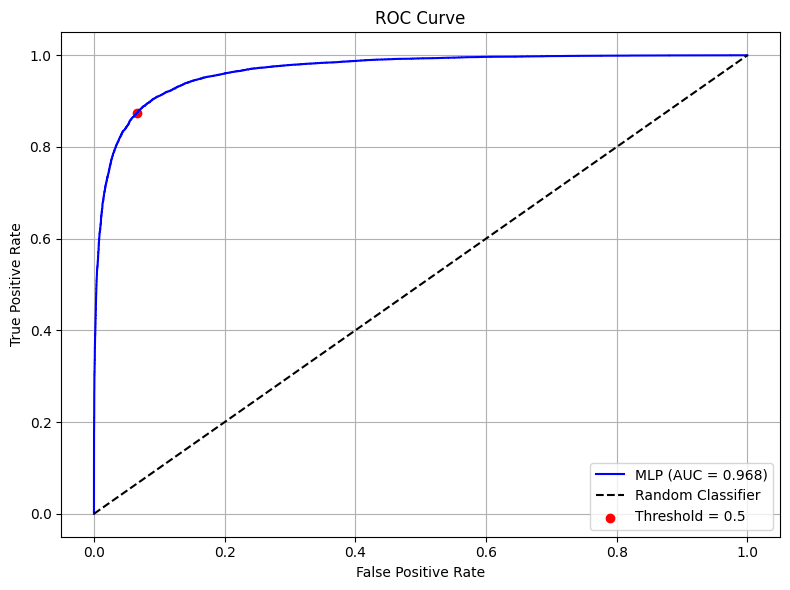

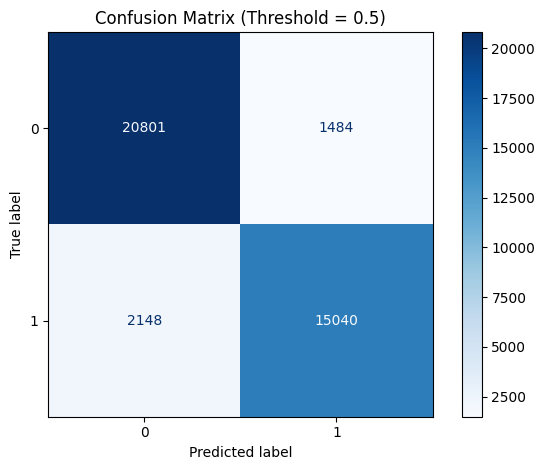

In [ ]:
from sklearn.metrics import roc_curve, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score
import matplotlib.pyplot as plt
import numpy as np


# Predict probabilities
y_proba = model.predict(X).ravel()

# ROC Curve
fpr, tpr, thresholds = roc_curve(y_array, y_proba)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"MLP (AUC = {roc_auc_score(y_array, y_proba):.3f})", color='blue')
plt.plot([0, 1], [0, 1], 'k--', label="Random Classifier")
plt.scatter(fpr[np.argmin(np.abs(thresholds - 0.5))],
            tpr[np.argmin(np.abs(thresholds - 0.5))],
            color='red', label="Threshold = 0.5")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Confusion Matrix
y_pred = (y_proba >= 0.5).astype(int)
cm = confusion_matrix(y_array, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap='Blues')
plt.title("Confusion Matrix (Threshold = 0.5)")
plt.grid(False)
plt.tight_layout()
plt.show()



model.save("best_model.h5")


## Final Model

<ipython-input-20-a335dbb37083>:11: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  y_bin = y.replace({'negative': 0, 'positive': 1}).astype(int)
<ipython-input-20-a335dbb37083>:11: FutureWarning: The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that preserve the categories. To change the categories, use ser.cat.rename_categories instead.
  y_bin = y.replace({'negative': 0, 'positive': 1}).astype(int)


Epoch 1/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - AUC: 0.8784 - loss: 0.4311 - val_AUC: 0.9566 - val_loss: 0.2638
Epoch 2/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - AUC: 0.9561 - loss: 0.2651 - val_AUC: 0.9615 - val_loss: 0.2466
Epoch 3/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - AUC: 0.9622 - loss: 0.2456 - val_AUC: 0.9648 - val_loss: 0.2359
Epoch 4/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - AUC: 0.9670 - loss: 0.2293 - val_AUC: 0.9661 - val_loss: 0.2339
Epoch 5/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - AUC: 0.9687 - loss: 0.2242 - val_AUC: 0.9680 - val_loss: 0.2244
Epoch 6/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - AUC: 0.9707 - loss: 0.2171 - val_AUC: 0.9694 - val_loss: 0.2207
Epoch 7/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - AUC: 0.9729 - loss: 0.2081 - val_AUC: 0.9707 - val_loss: 0.2160
Epoch 8/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - AUC: 0.9740 - loss: 0.2039 - val_AUC: 0.9716 - val_loss: 0.2111
Epoch 9/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - AU

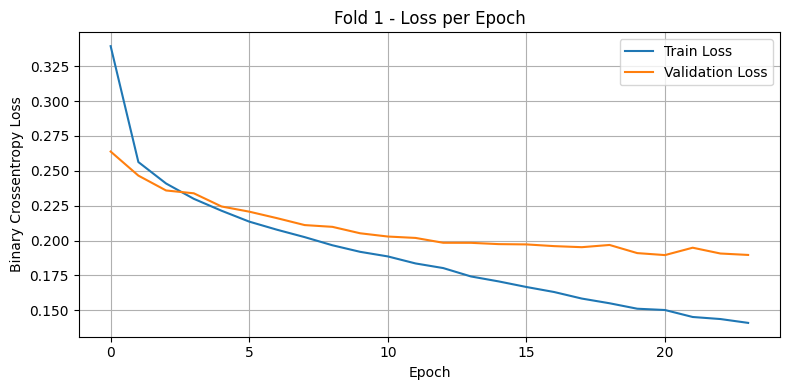

Epoch 1/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - AUC: 0.8836 - loss: 0.4272 - val_AUC: 0.9591 - val_loss: 0.2556
Epoch 2/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - AUC: 0.9568 - loss: 0.2631 - val_AUC: 0.9638 - val_loss: 0.2439
Epoch 3/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - AUC: 0.9629 - loss: 0.2434 - val_AUC: 0.9660 - val_loss: 0.2383
Epoch 4/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - AUC: 0.9650 - loss: 0.2372 - val_AUC: 0.9679 - val_loss: 0.2267
Epoch 5/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - AUC: 0.9689 - loss: 0.2227 - val_AUC: 0.9697 - val_loss: 0.2189
Epoch 6/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - AUC: 0.9719 - loss: 0.2127 - val_AUC: 0.9711 - val_loss: 0.2142
Epoch 7/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - AUC: 0.9730 - loss: 0.2076 - val_AUC: 0.9720 - val_loss: 0.2103
Epoch 8/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - AUC: 0.9760 - loss: 0.1959 - val_AUC: 0.9734 - val_loss: 0.2080
Epoch 9/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - AU

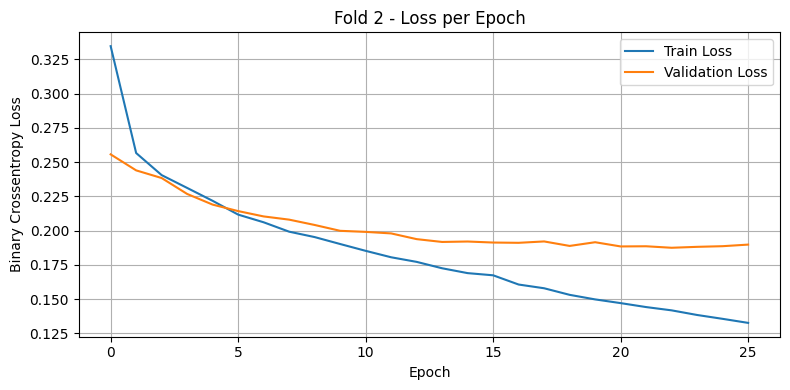

Epoch 1/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - AUC: 0.8709 - loss: 0.4383 - val_AUC: 0.9605 - val_loss: 0.2565
Epoch 2/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - AUC: 0.9570 - loss: 0.2619 - val_AUC: 0.9651 - val_loss: 0.2389
Epoch 3/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - AUC: 0.9616 - loss: 0.2472 - val_AUC: 0.9674 - val_loss: 0.2318
Epoch 4/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - AUC: 0.9661 - loss: 0.2329 - val_AUC: 0.9694 - val_loss: 0.2224
Epoch 5/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - AUC: 0.9665 - loss: 0.2302 - val_AUC: 0.9708 - val_loss: 0.2181
Epoch 6/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - AUC: 0.9714 - loss: 0.2140 - val_AUC: 0.9717 - val_loss: 0.2139
Epoch 7/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - AUC: 0.9729 - loss: 0.2070 - val_AUC: 0.9725 - val_loss: 0.2143
Epoch 8/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - AUC: 0.9741 - loss: 0.2031 - val_AUC: 0.9731 - val_loss: 0.2071
Epoch 9/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - AU

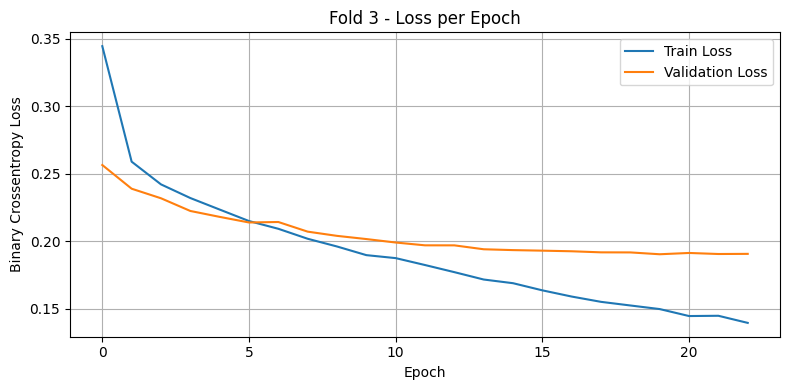

Epoch 1/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - AUC: 0.8785 - loss: 0.4301 - val_AUC: 0.9597 - val_loss: 0.2571
Epoch 2/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - AUC: 0.9579 - loss: 0.2587 - val_AUC: 0.9647 - val_loss: 0.2449
Epoch 3/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - AUC: 0.9648 - loss: 0.2368 - val_AUC: 0.9671 - val_loss: 0.2317
Epoch 4/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - AUC: 0.9678 - loss: 0.2268 - val_AUC: 0.9689 - val_loss: 0.2253
Epoch 5/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - AUC: 0.9688 - loss: 0.2231 - val_AUC: 0.9708 - val_loss: 0.2176
Epoch 6/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - AUC: 0.9724 - loss: 0.2104 - val_AUC: 0.9721 - val_loss: 0.2121
Epoch 7/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - AUC: 0.9735 - loss: 0.2057 - val_AUC: 0.9729 - val_loss: 0.2092
Epoch 8/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - AUC: 0.9760 - loss: 0.1961 - val_AUC: 0.9736 - val_loss: 0.2089
Epoch 9/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - A

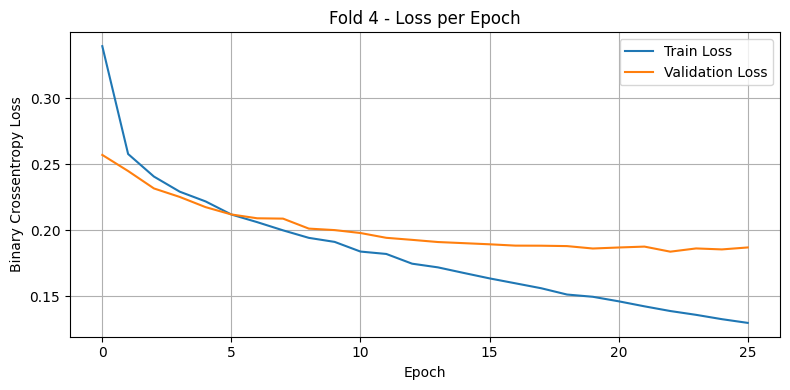

Epoch 1/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - AUC: 0.8809 - loss: 0.4309 - val_AUC: 0.9585 - val_loss: 0.2607
Epoch 2/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - AUC: 0.9581 - loss: 0.2582 - val_AUC: 0.9630 - val_loss: 0.2445
Epoch 3/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - AUC: 0.9617 - loss: 0.2462 - val_AUC: 0.9660 - val_loss: 0.2345
Epoch 4/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - AUC: 0.9683 - loss: 0.2255 - val_AUC: 0.9677 - val_loss: 0.2294
Epoch 5/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - AUC: 0.9695 - loss: 0.2199 - val_AUC: 0.9693 - val_loss: 0.2219
Epoch 6/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - AUC: 0.9704 - loss: 0.2168 - val_AUC: 0.9704 - val_loss: 0.2174
Epoch 7/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - AUC: 0.9727 - loss: 0.2080 - val_AUC: 0.9717 - val_loss: 0.2131
Epoch 8/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - AUC: 0.9738 - loss: 0.2044 - val_AUC: 0.9722 - val_loss: 0.2118
Epoch 9/50
494/494 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - AU

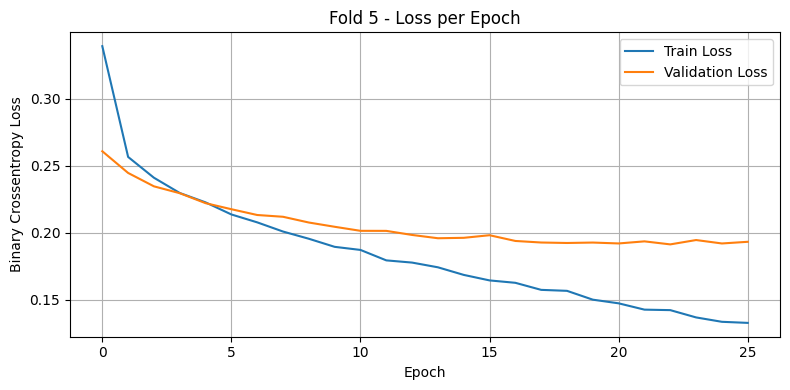

Train AUCs: [0.9911174944418382, 0.9927690945805372, 0.9913459461113264, 0.9929577806053291, 0.9929584149035394]
Validation AUCs: [0.9772598560897925, 0.978593261992985, 0.9774178521592731, 0.9792940123087396, 0.9775753296181813]
Mean Train AUC: 0.9922
Mean Validation AUC: 0.978
Epoch 1/20
617/617 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - AUC: 0.8886 - loss: 0.4108
Epoch 2/20
617/617 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - AUC: 0.9589 - loss: 0.2558
Epoch 3/20
617/617 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - AUC: 0.9640 - loss: 0.2390
Epoch 4/20
617/617 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - AUC: 0.9687 - loss: 0.2237
Epoch 5/20
617/617 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - AUC: 0.9698 - loss: 0.2194
Epoch 6/20
617/617 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - AUC: 0.9722 - loss: 0.2107
Epoch 7/20
617/617 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - AUC: 0.9749 - loss: 0.2000
Epoch 8/20
617/617 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - AUC: 0.9761 - loss: 0.1958
Epoch 9/20
617/617 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - AUC: 0.9778 - loss

In [ ]:
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
import numpy as np

X = df_model_improved.values
y_bin = y.replace({'negative': 0, 'positive': 1}).astype(int)
y_array = y_bin.values

def build_model():
    model = Sequential([
        Input(shape=(X.shape[1],)),
        Dense(100, activation='relu'),
        Dropout(0.5),
        Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer=Adam(learning_rate=0.001), loss='binary_crossentropy', metrics=['AUC'])
    return model

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
train_aucs, val_aucs = [], []

for fold_num, (train_idx, val_idx) in enumerate(cv.split(X, y_array), start=1):
    X_train, X_val = X[train_idx], X[val_idx]
    y_train, y_val = y_array[train_idx], y_array[val_idx]

    model = build_model()
    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=50,  # ⬅ increased number of epochs
        batch_size=64,
        verbose=1,
        callbacks=[EarlyStopping(patience=3, restore_best_weights=True)]
    )


    train_probs = model.predict(X_train).ravel()
    val_probs = model.predict(X_val).ravel()
    train_aucs.append(roc_auc_score(y_train, train_probs))
    val_aucs.append(roc_auc_score(y_val, val_probs))

    # 📊 Plot loss curves for this fold
    plt.figure(figsize=(8, 4))
    plt.plot(history.history['loss'], label='Train Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title(f"Fold {fold_num} - Loss per Epoch")
    plt.xlabel("Epoch")
    plt.ylabel("Binary Crossentropy Loss")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

print("Train AUCs:", train_aucs)
print("Validation AUCs:", val_aucs)
print("Mean Train AUC:", round(np.mean(train_aucs), 4))
print("Mean Validation AUC:", round(np.mean(val_aucs), 4))


# Train final model on ALL data for test prediction
final_model = build_model()
final_model.fit(X, y_array, epochs=20, batch_size=64, verbose=1)

# Save the trained model
final_model.save('final_model.h5')



1234/1234 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step


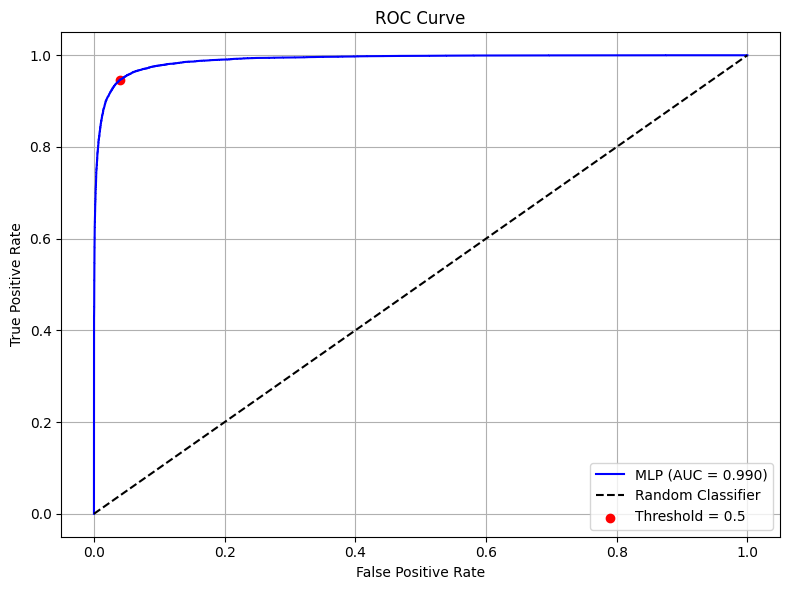

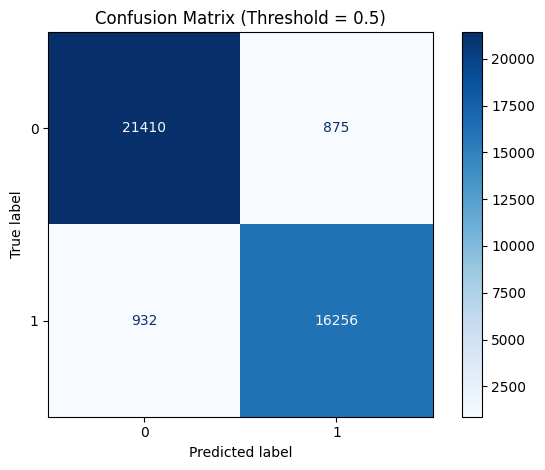

In [ ]:
from sklearn.metrics import roc_curve, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score
import matplotlib.pyplot as plt
import numpy as np


# Predict probabilities
y_proba = model.predict(X).ravel()

# ROC Curve
fpr, tpr, thresholds = roc_curve(y_array, y_proba)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f"MLP (AUC = {roc_auc_score(y_array, y_proba):.3f})", color='blue')
plt.plot([0, 1], [0, 1], 'k--', label="Random Classifier")
plt.scatter(fpr[np.argmin(np.abs(thresholds - 0.5))],
            tpr[np.argmin(np.abs(thresholds - 0.5))],
            color='red', label="Threshold = 0.5")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Confusion Matrix
y_pred = (y_proba >= 0.5).astype(int)
cm = confusion_matrix(y_array, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap='Blues')
plt.title("Confusion Matrix (Threshold = 0.5)")
plt.grid(False)
plt.tight_layout()
plt.show()



model.save("best_model.h5")


# Clustering

### Numeric Featurs

Numeric Featurs + manhattan distance (Silhouette)

K = 2 → Silhouette Score = 0.2766
K = 3 → Silhouette Score = 0.1715
K = 4 → Silhouette Score = 0.1299
K = 5 → Silhouette Score = 0.1061
K = 6 → Silhouette Score = 0.0797
K = 7 → Silhouette Score = 0.0631


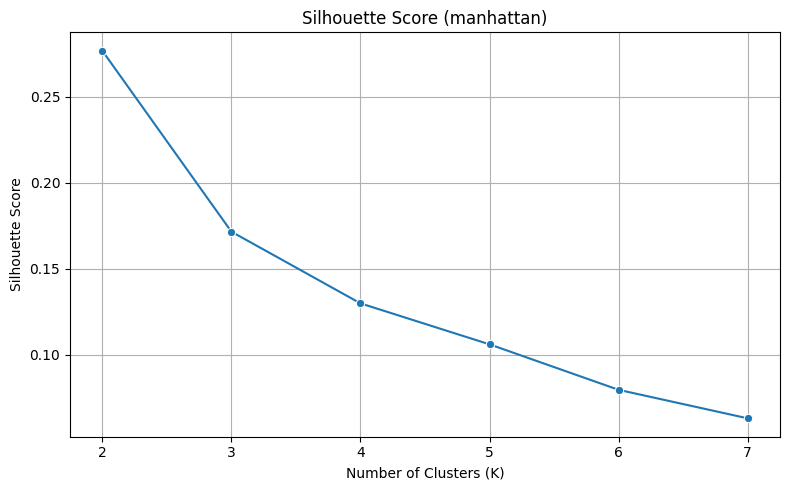

In [ ]:
from sklearn_extra.cluster import KMedoids
from sklearn.metrics import silhouette_score
from sklearn.metrics import pairwise_distances
import matplotlib.pyplot as plt
import seaborn as sns

# Sample the data (10000 rows to save memory)
df_sampled = df_model.sample(n=10000, random_state=42)

# Selected features
cluster_features = [
    'pos_score_scaled',
    'neg_score_scaled',
    'followers_scaled',
    'previous_posts_count_scaled',
    'hashtag_count_scaled'
]
X_cluster = df_sampled[cluster_features]

# Compute distance matrix (Manhattan distance as explained in slide 21)
distance_matrix = pairwise_distances(X_cluster, metric='manhattan')

# Run K-Medoids for multiple values of K
K_range = range(2, 8)
silhouette_scores = []

for k in K_range:
    kmedoids = KMedoids(n_clusters=k, metric='precomputed', random_state=42)
    kmedoids.fit(distance_matrix)
    labels = kmedoids.labels_
    score = silhouette_score(distance_matrix, labels, metric='precomputed')
    silhouette_scores.append(score)
    print(f"K = {k} → Silhouette Score = {score:.4f}")

# Plot silhouette scores
plt.figure(figsize=(8, 5))
sns.lineplot(x=list(K_range), y=silhouette_scores, marker='o')
plt.title("Silhouette Score (manhattan)")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.grid(True)
plt.tight_layout()
plt.show()

Numeric Featurs + manhattan distance (Davies-Bouldin)



K = 2 → Davies-Bouldin Index = 2.0264
K = 3 → Davies-Bouldin Index = 2.9755
K = 4 → Davies-Bouldin Index = 3.6822
K = 5 → Davies-Bouldin Index = 4.4361
K = 6 → Davies-Bouldin Index = 5.4426
K = 7 → Davies-Bouldin Index = 6.3595


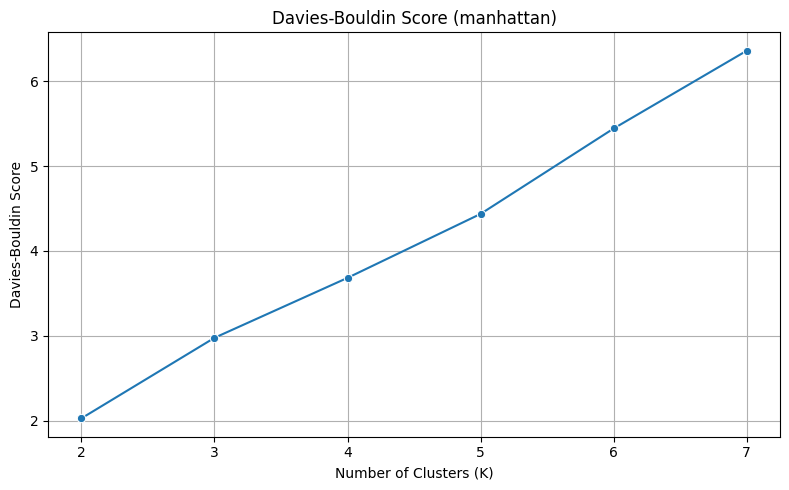

In [ ]:
from sklearn.metrics import davies_bouldin_score

K_range = range(2, 8)
db_scores = []

for k in K_range:
    kmedoids = KMedoids(n_clusters=k, metric='manhattan', random_state=42)
    labels = kmedoids.fit_predict(X_cluster)
    score = davies_bouldin_score(X_cluster, labels)
    db_scores.append(score)
    print(f"K = {k} → Davies-Bouldin Index = {score:.4f}")

plt.figure(figsize=(8, 5))
sns.lineplot(x=list(K_range), y=db_scores, marker='o')
plt.title("Davies-Bouldin Score (manhattan)")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Davies-Bouldin Score")
plt.grid(True)
plt.tight_layout()
plt.show()


PCA + plot

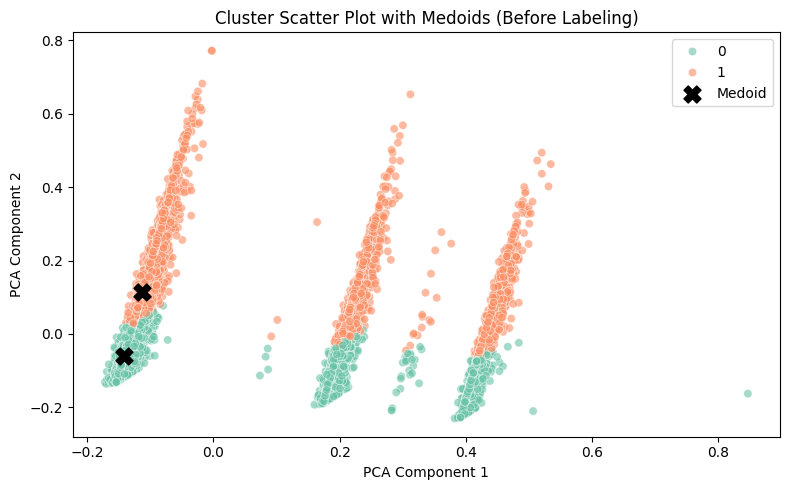

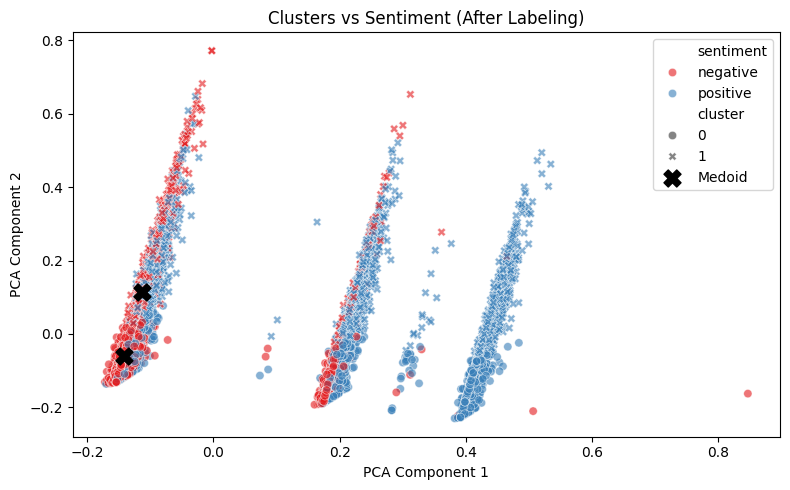

In [ ]:

np.fill_diagonal(distance_matrix, 0)

# Run K-Medoids with K=2 (use best K)
best_k = 2
kmedoids = KMedoids(n_clusters=best_k, metric='precomputed', random_state=42)
kmedoids.fit(distance_matrix)
labels = kmedoids.labels_
medoid_indices = kmedoids.medoid_indices_

# Project to 2D using PCA
pca = PCA(n_components=2)
X_2D = pca.fit_transform(X_cluster)
X_medoids_2D = pca.transform(X_cluster.iloc[medoid_indices])

# Plot 1: Scatter before sentiment labels (just clusters)
plt.figure(figsize=(8, 5))
sns.scatterplot(x=X_2D[:, 0], y=X_2D[:, 1], hue=labels, palette='Set2', alpha=0.6)
plt.scatter(X_medoids_2D[:, 0], X_medoids_2D[:, 1],
            c='black', s=150, marker='X', label='Medoid')
plt.title("Cluster Scatter Plot with Medoids (Before Labeling)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.legend()
plt.tight_layout()
plt.show()

# Add cluster labels to data
df_eval = df.loc[df_sampled.index].copy()
df_eval['cluster'] = labels

# Plot 2: Scatter after labeling (sentiment vs cluster)
plt.figure(figsize=(8, 5))
sns.scatterplot(x=X_2D[:, 0], y=X_2D[:, 1],
                hue=df_eval['sentiment'], style=df_eval['cluster'],
                palette='Set1', alpha=0.6)
plt.scatter(X_medoids_2D[:, 0], X_medoids_2D[:, 1],
            c='black', s=150, marker='X', label='Medoid')
plt.title("Clusters vs Sentiment (After Labeling)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

# Convert sentiment to numeric labels for evaluation
true_labels = df_eval['sentiment'].astype('category').cat.codes
predicted_labels = df_eval['cluster']

# Compute ARI and NMI
ari = adjusted_rand_score(true_labels, predicted_labels)
nmi = normalized_mutual_info_score(true_labels, predicted_labels)

# Print evaluation
print("📊 Cluster vs Sentiment Table:")
print(pd.crosstab(df_eval['cluster'], df_eval['sentiment']))
print(f"\n Adjusted Rand Index (ARI): {ari:.4f}")
print(f"Normalized Mutual Information (NMI): {nmi:.4f}")


📊 Cluster vs Sentiment Table:
sentiment  negative  positive
cluster                      
0              4349      2028
1              1287      2336

 Adjusted Rand Index (ARI): 0.1124
Normalized Mutual Information (NMI): 0.0754


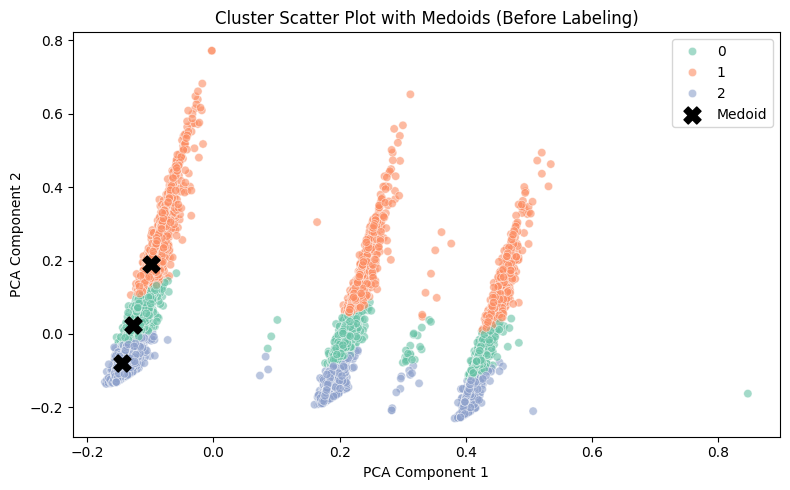

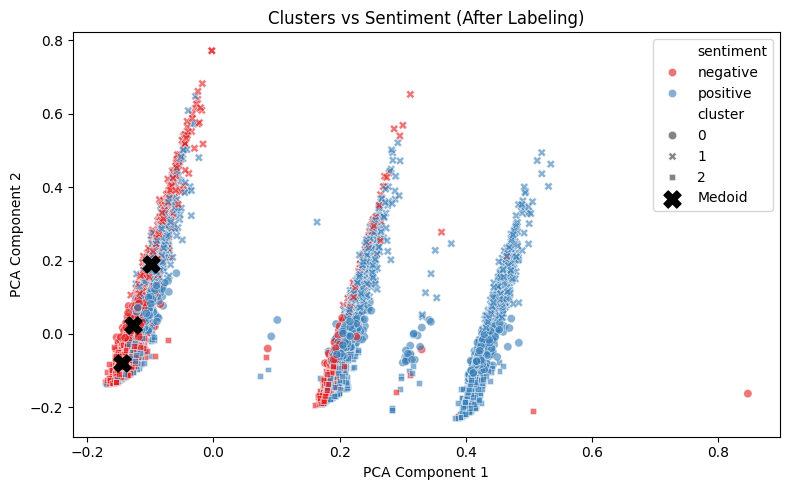

In [ ]:

np.fill_diagonal(distance_matrix, 0)

# Run K-Medoids with K=3
best_k = 3
kmedoids = KMedoids(n_clusters=best_k, metric='precomputed', random_state=42)
kmedoids.fit(distance_matrix)
labels = kmedoids.labels_
medoid_indices = kmedoids.medoid_indices_

# Project to 2D using PCA
pca = PCA(n_components=2)
X_2D = pca.fit_transform(X_cluster)
X_medoids_2D = pca.transform(X_cluster.iloc[medoid_indices])

# Plot 1: Scatter before sentiment labels (just clusters)
plt.figure(figsize=(8, 5))
sns.scatterplot(x=X_2D[:, 0], y=X_2D[:, 1], hue=labels, palette='Set2', alpha=0.6)
plt.scatter(X_medoids_2D[:, 0], X_medoids_2D[:, 1],
            c='black', s=150, marker='X', label='Medoid')
plt.title("Cluster Scatter Plot with Medoids (Before Labeling)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.legend()
plt.tight_layout()
plt.show()

# Add cluster labels to data
df_eval = df.loc[df_sampled.index].copy()
df_eval['cluster'] = labels

# Plot 2: Scatter after labeling (sentiment vs cluster)
plt.figure(figsize=(8, 5))
sns.scatterplot(x=X_2D[:, 0], y=X_2D[:, 1],
                hue=df_eval['sentiment'], style=df_eval['cluster'],
                palette='Set1', alpha=0.6)
plt.scatter(X_medoids_2D[:, 0], X_medoids_2D[:, 1],
            c='black', s=150, marker='X', label='Medoid')
plt.title("Clusters vs Sentiment (After Labeling)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

# Convert sentiment to numeric labels for evaluation
true_labels = df_eval['sentiment'].astype('category').cat.codes
predicted_labels = df_eval['cluster']

# Compute ARI and NMI
ari = adjusted_rand_score(true_labels, predicted_labels)
nmi = normalized_mutual_info_score(true_labels, predicted_labels)

# Print evaluation
print("📊 Cluster vs Sentiment Table:")
print(pd.crosstab(df_eval['cluster'], df_eval['sentiment']))
print(f"\n Adjusted Rand Index (ARI): {ari:.4f}")
print(f"Normalized Mutual Information (NMI): {nmi:.4f}")


📊 Cluster vs Sentiment Table:
sentiment  negative  positive
cluster                      
0              1701      1847
1               641      1336
2              3294      1181

 Adjusted Rand Index (ARI): 0.0871
Normalized Mutual Information (NMI): 0.0653


### Numeric + Binary + Catagorial featurs

Numeric + Binary + Catagorial featurs - using Gower distance (Silhouette)

[Gower] K = 2 → Silhouette Score = 0.1443
[Gower] K = 3 → Silhouette Score = 0.0796
[Gower] K = 4 → Silhouette Score = 0.0553
[Gower] K = 5 → Silhouette Score = 0.0339
[Gower] K = 6 → Silhouette Score = 0.0176
[Gower] K = 7 → Silhouette Score = 0.0136


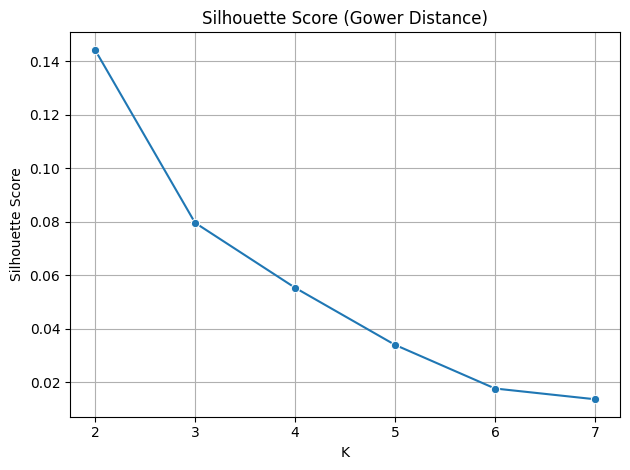

In [ ]:
import gower
from sklearn_extra.cluster import KMedoids
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import seaborn as sns

# Features for Gower distance
metadata_features = [
    'pos_score_scaled', 'neg_score_scaled', 'followers_scaled',
    'previous_posts_count_scaled', 'hashtag_count_scaled',
    'checkmark_grey', 'checkmark_gold', 'has_profile_pic'
]

df_sampled = df_model.sample(n=10000, random_state=42)
X_meta = df_sampled[metadata_features]

# Compute Gower distance matrix
gower_matrix = gower.gower_matrix(X_meta)

# Run K-Medoids
K_range = range(2, 8)
silhouette_scores_gower = []

for k in K_range:
    kmedoids = KMedoids(n_clusters=k, metric='precomputed', random_state=42)
    kmedoids.fit(gower_matrix)
    score = silhouette_score(gower_matrix, kmedoids.labels_, metric='precomputed')
    silhouette_scores_gower.append(score)
    print(f"[Gower] K = {k} → Silhouette Score = {score:.4f}")

# Plot
plt.figure()
sns.lineplot(x=list(K_range), y=silhouette_scores_gower, marker='o')
plt.title("Silhouette Score (Gower Distance)")
plt.xlabel("K")
plt.ylabel("Silhouette Score")
plt.grid(True)
plt.tight_layout()
plt.show()



Numeric + Binary + Catagorial featurs - using Gower distance (Davies-Bouldin)

[Gower] K = 2 → Davies-Bouldin Index = 4.3770
[Gower] K = 3 → Davies-Bouldin Index = 6.4359
[Gower] K = 4 → Davies-Bouldin Index = 8.2656
[Gower] K = 5 → Davies-Bouldin Index = 10.7761
[Gower] K = 6 → Davies-Bouldin Index = 13.0733
[Gower] K = 7 → Davies-Bouldin Index = 13.6383


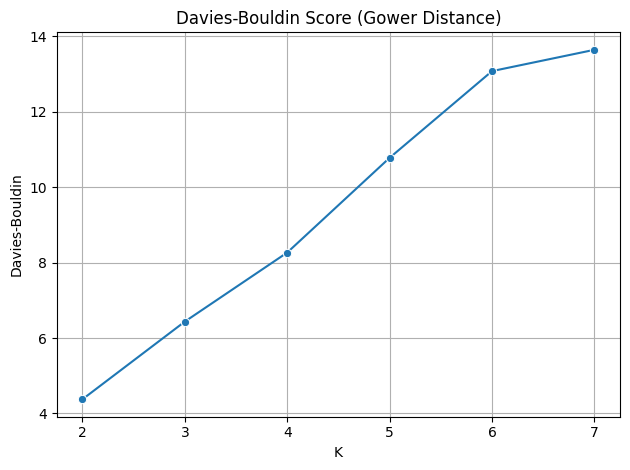

In [ ]:
from sklearn.metrics import davies_bouldin_score
from sklearn_extra.cluster import KMedoids
import gower

dbi_scores_gower = []

for k in K_range:
    kmedoids = KMedoids(n_clusters=k, metric='precomputed', random_state=42)
    kmedoids.fit(gower_matrix)
    labels = kmedoids.labels_

    # Use original vectors for DBI
    dbi = davies_bouldin_score(X_meta, labels)
    dbi_scores_gower.append(dbi)
    print(f"[Gower] K = {k} → Davies-Bouldin Index = {dbi:.4f}")

# Plot
plt.figure()
sns.lineplot(x=list(K_range), y=dbi_scores_gower, marker='o')
plt.title("Davies-Bouldin Score (Gower Distance)")
plt.xlabel("K")
plt.ylabel("Davies-Bouldin")
plt.grid(True)
plt.tight_layout()
plt.show()


Numeric + Binary + Catagorial featurs - PCA and PLOT

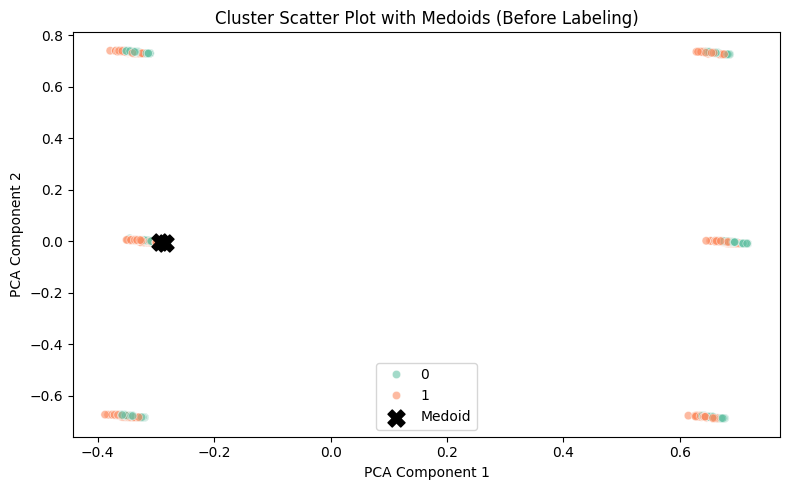

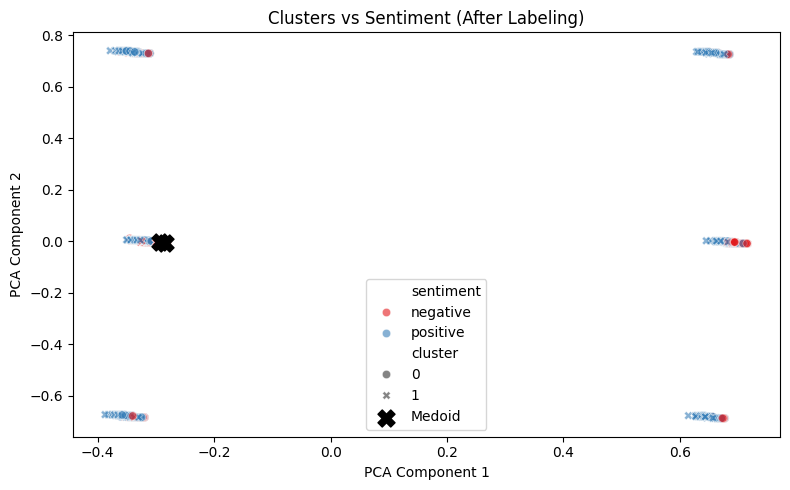

📊 Cluster vs Sentiment Table:
sentiment  negative  positive
cluster                      
0              4349      2028
1              1287      2336

🔍 Adjusted Rand Index (ARI): 0.1124
🔍 Normalized Mutual Information (NMI): 0.0754


In [ ]:
import gower
from sklearn_extra.cluster import KMedoids
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

# Features for Gower distance
metadata_features = [
    'pos_score_scaled', 'neg_score_scaled', 'followers_scaled',
    'previous_posts_count_scaled', 'hashtag_count_scaled',
    'checkmark_grey', 'checkmark_gold', 'has_profile_pic'
]

# Sample the data
df_sampled = df_model.sample(n=10000, random_state=42)
X_meta = df_sampled[metadata_features]

# Compute Gower distance
gower_matrix = gower.gower_matrix(X_meta)

# Run K-Medoids with best K (based on silhouette)
best_k = 2
kmedoids = KMedoids(n_clusters=best_k, metric='precomputed', random_state=42)
kmedoids.fit(gower_matrix)
labels = kmedoids.labels_
medoid_indices = kmedoids.medoid_indices_

# PCA projection
pca = PCA(n_components=2)
X_2D = pca.fit_transform(X_meta)
X_medoids_2D = pca.transform(X_meta.iloc[medoid_indices])

# Plot 1: BEFORE sentiment labeling
plt.figure(figsize=(8, 5))
sns.scatterplot(x=X_2D[:, 0], y=X_2D[:, 1], hue=labels, palette='Set2', alpha=0.6)
plt.scatter(X_medoids_2D[:, 0], X_medoids_2D[:, 1],
            c='black', s=150, marker='X', label='Medoid')
plt.title("Cluster Scatter Plot with Medoids (Before Labeling)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.legend()
plt.tight_layout()
plt.show()

# Add sentiment to clustered data
df_eval = df.loc[df_sampled.index].copy()
df_eval['cluster'] = labels

# Plot 2: AFTER sentiment labeling
plt.figure(figsize=(8, 5))
sns.scatterplot(x=X_2D[:, 0], y=X_2D[:, 1],
                hue=df_eval['sentiment'],
                style=df_eval['cluster'],
                palette='Set1', alpha=0.6)
plt.scatter(X_medoids_2D[:, 0], X_medoids_2D[:, 1],
            c='black', s=150, marker='X', label='Medoid')
plt.title("Clusters vs Sentiment (After Labeling)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.legend()
plt.tight_layout()
plt.show()

# Evaluation metrics
true_labels = df_eval['sentiment'].astype('category').cat.codes
predicted_labels = df_eval['cluster']

ari = adjusted_rand_score(true_labels, predicted_labels)
nmi = normalized_mutual_info_score(true_labels, predicted_labels)

print("📊 Cluster vs Sentiment Table:")
print(pd.crosstab(df_eval['cluster'], df_eval['sentiment']))
print(f"\n🔍 Adjusted Rand Index (ARI): {ari:.4f}")
print(f"🔍 Normalized Mutual Information (NMI): {nmi:.4f}")


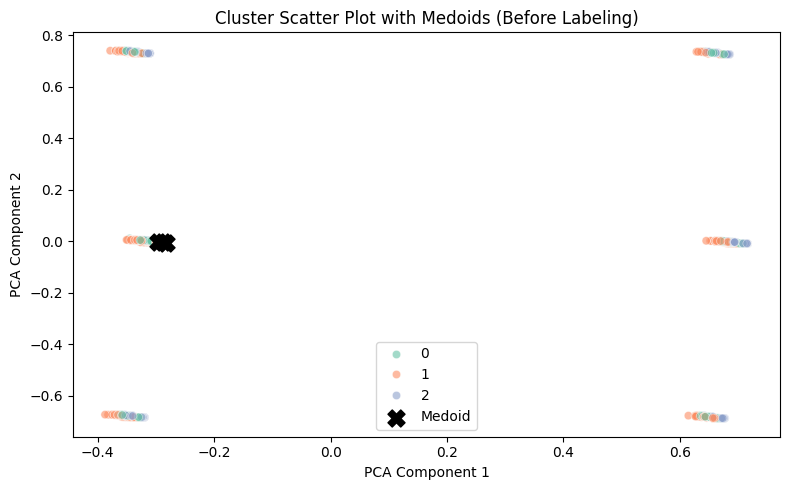

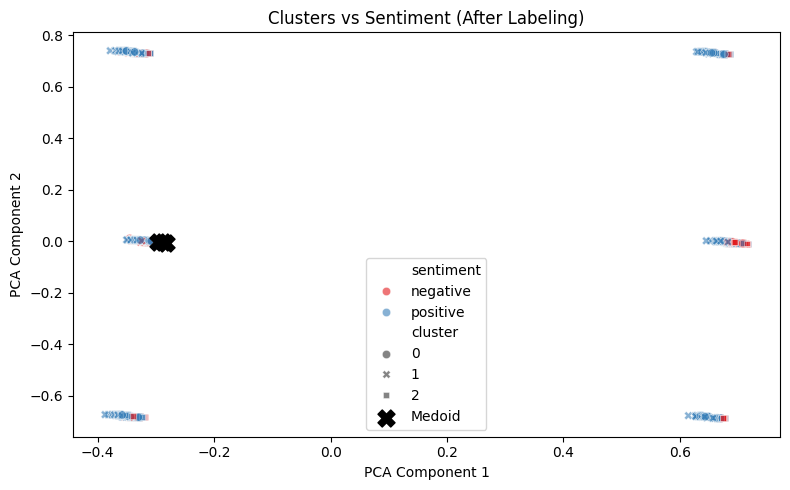

📊 Cluster vs Sentiment Table:
sentiment  negative  positive
cluster                      
0              1701      1847
1               641      1336
2              3294      1181

🔍 Adjusted Rand Index (ARI): 0.0871
🔍 Normalized Mutual Information (NMI): 0.0653


In [ ]:
import gower
from sklearn_extra.cluster import KMedoids
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

# Features for Gower distance
metadata_features = [
    'pos_score_scaled', 'neg_score_scaled', 'followers_scaled',
    'previous_posts_count_scaled', 'hashtag_count_scaled',
    'checkmark_grey', 'checkmark_gold', 'has_profile_pic'
]

# Sample the data
df_sampled = df_model.sample(n=10000, random_state=42)
X_meta = df_sampled[metadata_features]

# Compute Gower distance
gower_matrix = gower.gower_matrix(X_meta)

# Run K-Medoids with best K (based on silhouette)
best_k = 3
kmedoids = KMedoids(n_clusters=best_k, metric='precomputed', random_state=42)
kmedoids.fit(gower_matrix)
labels = kmedoids.labels_
medoid_indices = kmedoids.medoid_indices_

# PCA projection
pca = PCA(n_components=2)
X_2D = pca.fit_transform(X_meta)
X_medoids_2D = pca.transform(X_meta.iloc[medoid_indices])

# Plot 1: BEFORE sentiment labeling
plt.figure(figsize=(8, 5))
sns.scatterplot(x=X_2D[:, 0], y=X_2D[:, 1], hue=labels, palette='Set2', alpha=0.6)
plt.scatter(X_medoids_2D[:, 0], X_medoids_2D[:, 1],
            c='black', s=150, marker='X', label='Medoid')
plt.title("Cluster Scatter Plot with Medoids (Before Labeling)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.legend()
plt.tight_layout()
plt.show()

# Add sentiment to clustered data
df_eval = df.loc[df_sampled.index].copy()
df_eval['cluster'] = labels

# Plot 2: AFTER sentiment labeling
plt.figure(figsize=(8, 5))
sns.scatterplot(x=X_2D[:, 0], y=X_2D[:, 1],
                hue=df_eval['sentiment'],
                style=df_eval['cluster'],
                palette='Set1', alpha=0.6)
plt.scatter(X_medoids_2D[:, 0], X_medoids_2D[:, 1],
            c='black', s=150, marker='X', label='Medoid')
plt.title("Clusters vs Sentiment (After Labeling)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.legend()
plt.tight_layout()
plt.show()

# Evaluation metrics
true_labels = df_eval['sentiment'].astype('category').cat.codes
predicted_labels = df_eval['cluster']

ari = adjusted_rand_score(true_labels, predicted_labels)
nmi = normalized_mutual_info_score(true_labels, predicted_labels)

print("📊 Cluster vs Sentiment Table:")
print(pd.crosstab(df_eval['cluster'], df_eval['sentiment']))
print(f"\n🔍 Adjusted Rand Index (ARI): {ari:.4f}")
print(f"🔍 Normalized Mutual Information (NMI): {nmi:.4f}")


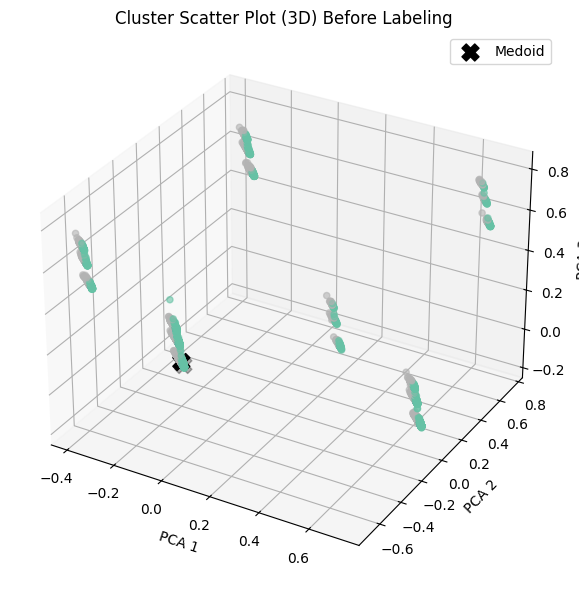

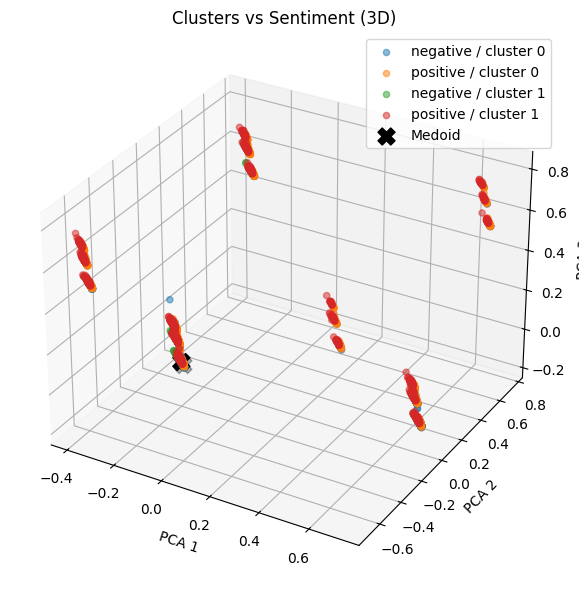

In [ ]:
from mpl_toolkits.mplot3d import Axes3D  # needed for 3D plotting

# --- PCA projection into 3D ---
pca_3d = PCA(n_components=3)
X_3D = pca_3d.fit_transform(X_meta)
X_medoids_3D = pca_3d.transform(X_meta.iloc[medoid_indices])

# --- 3D Plot 1: Clusters only ---
fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(111, projection='3d')
scatter = ax.scatter(X_3D[:, 0], X_3D[:, 1], X_3D[:, 2],
                     c=labels, cmap='Set2', alpha=0.6)
ax.scatter(X_medoids_3D[:, 0], X_medoids_3D[:, 1], X_medoids_3D[:, 2],
           c='black', s=150, marker='X', label='Medoid')
ax.set_title("Cluster Scatter Plot (3D) Before Labeling")
ax.set_xlabel("PCA 1")
ax.set_ylabel("PCA 2")
ax.set_zlabel("PCA 3")
plt.legend()
plt.tight_layout()
plt.show()

# --- 3D Plot 2: Clusters vs Sentiment ---
from matplotlib import cm
fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(111, projection='3d')
sentiment_color = df_eval['sentiment'].astype('category').cat.codes
cluster_marker = df_eval['cluster'].map({0: 'o', 1: '^'})  # marker style per cluster

for cluster in df_eval['cluster'].unique():
    for sentiment in df_eval['sentiment'].unique():
        mask = (df_eval['cluster'] == cluster) & (df_eval['sentiment'] == sentiment)
        ax.scatter(X_3D[mask, 0], X_3D[mask, 1], X_3D[mask, 2],
                   label=f'{sentiment} / cluster {cluster}',
                   alpha=0.5)

ax.scatter(X_medoids_3D[:, 0], X_medoids_3D[:, 1], X_medoids_3D[:, 2],
           c='black', s=150, marker='X', label='Medoid')
ax.set_title("Clusters vs Sentiment (3D)")
ax.set_xlabel("PCA 1")
ax.set_ylabel("PCA 2")
ax.set_zlabel("PCA 3")
plt.legend()
plt.tight_layout()
plt.show()


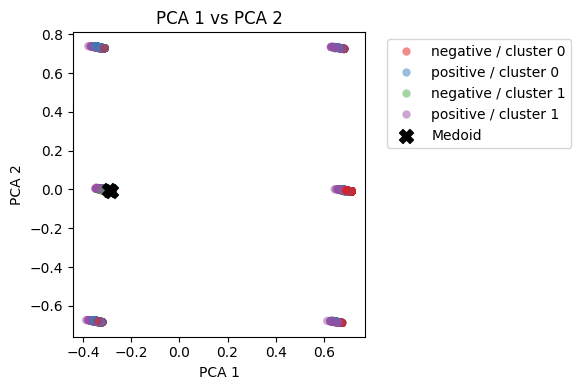

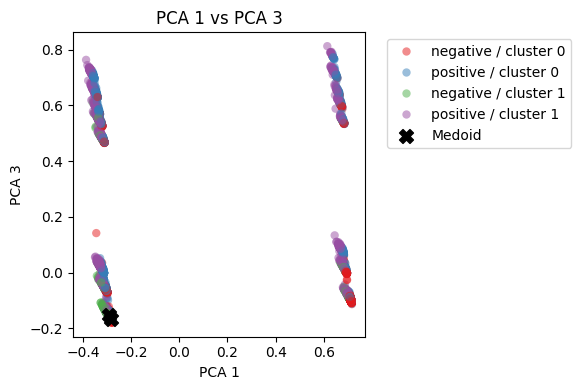

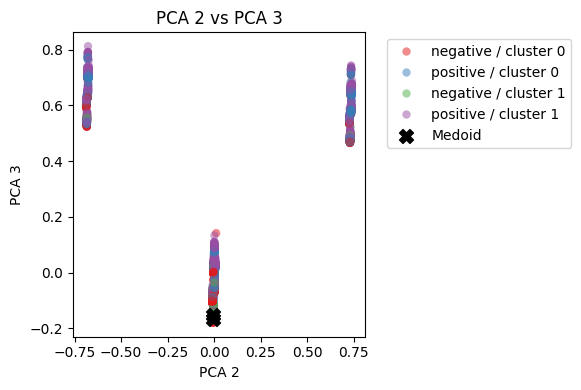

In [ ]:
pairs = [(0, 1), (0, 2), (1, 2)]
labels_map = df_eval[['sentiment', 'cluster']].astype(str)
labels_combo = labels_map['sentiment'] + " / cluster " + labels_map['cluster'].astype(str)

for i, (x, y) in enumerate(pairs):
    plt.figure(figsize=(6, 4))
    sns.scatterplot(
        x=X_3D[:, x], y=X_3D[:, y],
        hue=labels_combo,
        palette='Set1', alpha=0.5, linewidth=0
    )
    plt.scatter(X_medoids_3D[:, x], X_medoids_3D[:, y],
                c='black', s=100, marker='X', label='Medoid')
    plt.xlabel(f"PCA {x+1}")
    plt.ylabel(f"PCA {y+1}")
    plt.title(f"PCA {x+1} vs PCA {y+1}")
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()


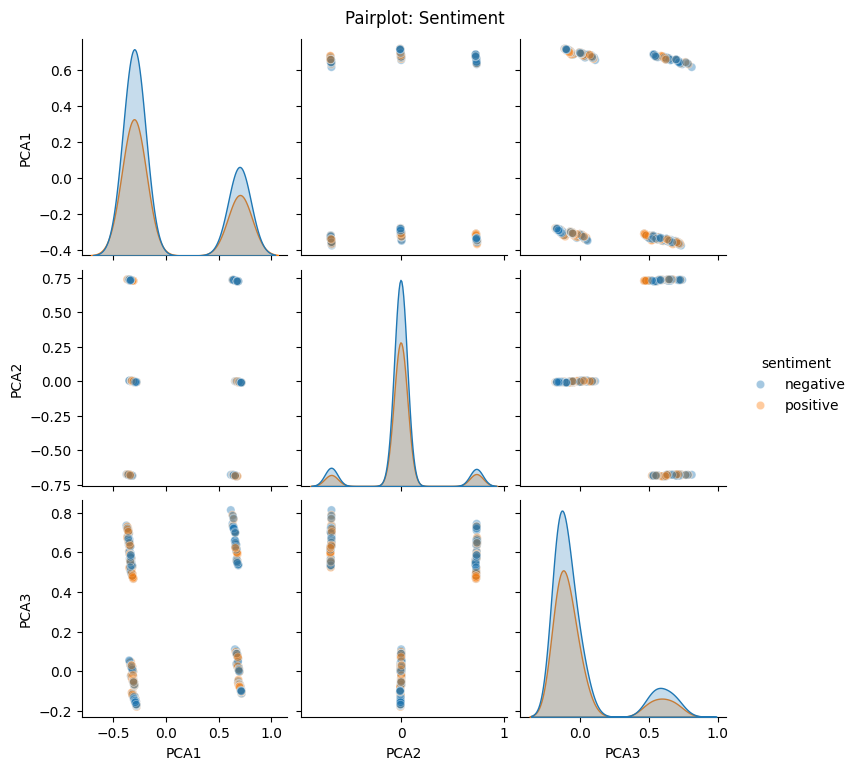

In [ ]:
pca_df = pd.DataFrame(X_3D, columns=["PCA1", "PCA2", "PCA3"])
pca_df['sentiment'] = df_eval['sentiment']
pca_df['cluster'] = df_eval['cluster'].astype(str)

sns.pairplot(pca_df, hue='sentiment', vars=["PCA1", "PCA2", "PCA3"], plot_kws={'alpha': 0.4})
plt.suptitle("Pairplot: Sentiment", y=1.02)
plt.show()


### N-gram features

N-gram features - euclidean distance (Davies-Bouldin)

[N-gram] K = 2 → Davies-Bouldin Index = 4.1366
[N-gram] K = 3 → Davies-Bouldin Index = 14.8655
[N-gram] K = 4 → Davies-Bouldin Index = 14.9143
[N-gram] K = 5 → Davies-Bouldin Index = 14.2082
[N-gram] K = 6 → Davies-Bouldin Index = 13.7110
[N-gram] K = 7 → Davies-Bouldin Index = 13.1867


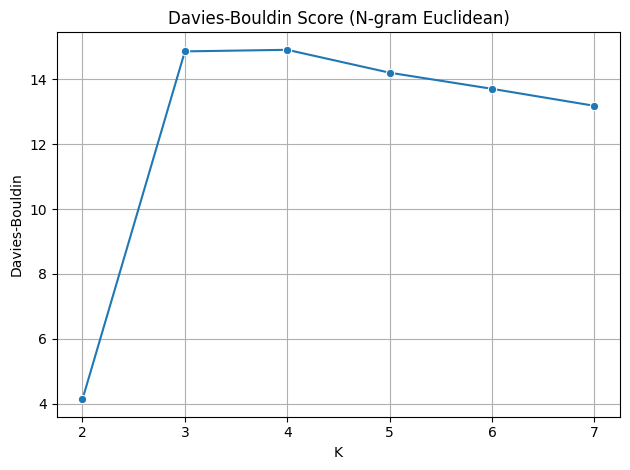

In [ ]:
ngram_cols = [col for col in df_model.columns if col.startswith('svd_')]
X_ngrams = df_model.loc[df_sampled.index, ngram_cols]


dbi_scores_ngram = []
X_ngrams = df_sampled[ngram_cols]

for k in K_range:
    kmedoids = KMedoids(n_clusters=k, metric='euclidean', random_state=42)
    kmedoids.fit(X_ngrams)
    labels = kmedoids.labels_

    dbi = davies_bouldin_score(X_ngrams, labels)
    dbi_scores_ngram.append(dbi)
    print(f"[N-gram] K = {k} → Davies-Bouldin Index = {dbi:.4f}")

# Plot
plt.figure()
sns.lineplot(x=list(K_range), y=dbi_scores_ngram, marker='o')
plt.title("Davies-Bouldin Score (N-gram Euclidean)")
plt.xlabel("K")
plt.ylabel("Davies-Bouldin")
plt.grid(True)
plt.tight_layout()
plt.show()


N-gram features - euclidean distance (Silhouette)

[N-gram] K = 2 → Silhouette Score = -0.3056
[N-gram] K = 3 → Silhouette Score = -0.3048
[N-gram] K = 4 → Silhouette Score = -0.3042
[N-gram] K = 5 → Silhouette Score = -0.3035
[N-gram] K = 6 → Silhouette Score = -0.3030
[N-gram] K = 7 → Silhouette Score = -0.3024


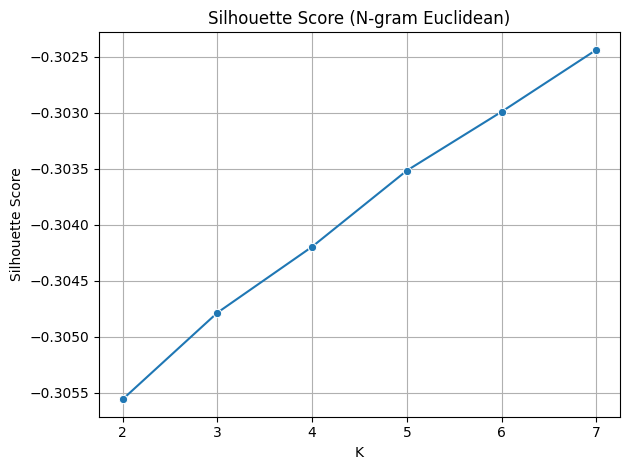

In [ ]:
# Compute Euclidean distance matrix
distance_matrix = pairwise_distances(X_ngrams, metric='euclidean')
np.fill_diagonal(distance_matrix, 0)  # ← fix the diagonal

# Run K-Medoids
silhouette_scores_ngram = []

for k in K_range:
    kmedoids = KMedoids(n_clusters=k, metric='precomputed', random_state=42)
    kmedoids.fit(distance_matrix)
    score = silhouette_score(distance_matrix, kmedoids.labels_, metric='precomputed')
    silhouette_scores_ngram.append(score)
    print(f"[N-gram] K = {k} → Silhouette Score = {score:.4f}")

# Plot
plt.figure()
sns.lineplot(x=list(K_range), y=silhouette_scores_ngram, marker='o')
plt.title("Silhouette Score (N-gram Euclidean)")
plt.xlabel("K")
plt.ylabel("Silhouette Score")
plt.grid(True)
plt.tight_layout()
plt.show()


N-gram - PCA and PLOT

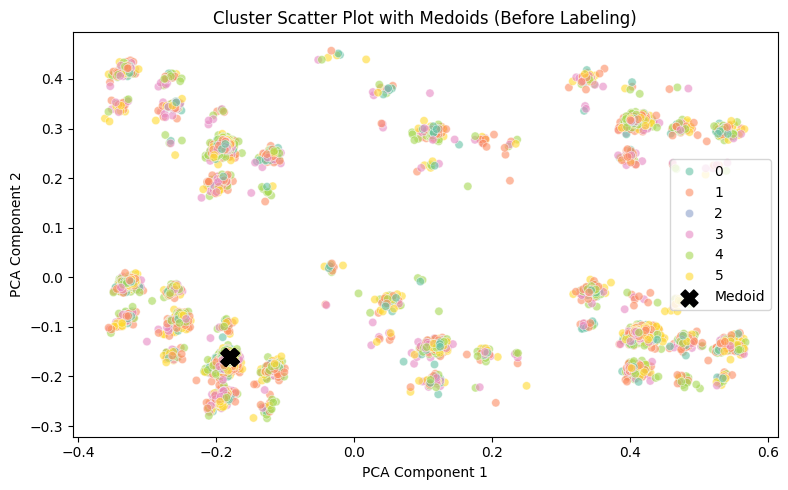

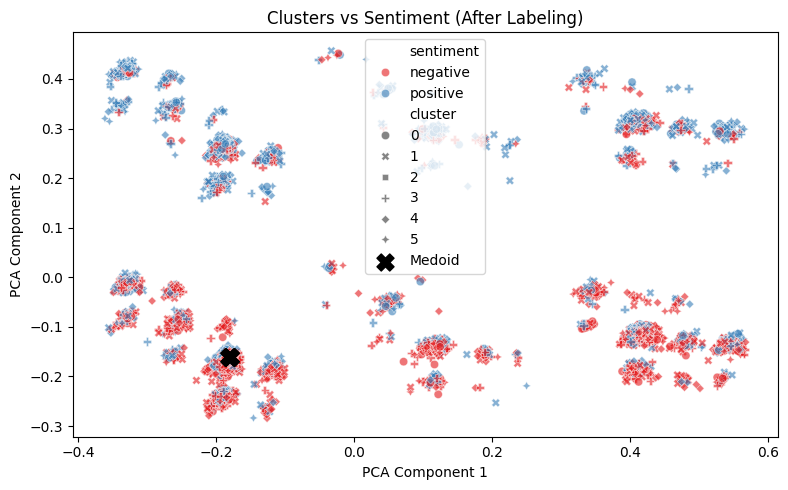

📊 Cluster vs Sentiment Table:
sentiment  negative  positive
cluster                      
0               860       668
1              1500      1184
2                 1         0
3              1123       710
4              1089      1031
5              1063       771

🔍 Adjusted Rand Index (ARI): 0.0010
🔍 Normalized Mutual Information (NMI): 0.0019


In [ ]:
from sklearn_extra.cluster import KMedoids
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

# --- Load n-gram features ---
ngram_cols = [col for col in df_model.columns if col.startswith('svd_')]
X_ngrams = df_model.loc[df_sampled.index, ngram_cols]

# --- Run K-Medoids with chosen K ---
best_k = 2
kmedoids = KMedoids(n_clusters=best_k, metric='euclidean', random_state=42)
kmedoids.fit(X_ngrams)
labels = kmedoids.labels_
medoid_indices = kmedoids.medoid_indices_

# --- PCA for 2D plotting ---
pca = PCA(n_components=2)
X_2D = pca.fit_transform(X_ngrams)
X_medoids_2D = pca.transform(X_ngrams.iloc[medoid_indices])

# --- Plot 1: Clusters only ---
plt.figure(figsize=(8, 5))
sns.scatterplot(x=X_2D[:, 0], y=X_2D[:, 1], hue=labels, palette='Set2', alpha=0.6)
plt.scatter(X_medoids_2D[:, 0], X_medoids_2D[:, 1], c='black', s=150, marker='X', label='Medoid')
plt.title("Cluster Scatter Plot with Medoids (Before Labeling)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.legend()
plt.tight_layout()
plt.show()

# --- Plot 2: Clusters vs Sentiment ---
df_eval = df.loc[df_sampled.index].copy()
df_eval['cluster'] = labels

plt.figure(figsize=(8, 5))
sns.scatterplot(x=X_2D[:, 0], y=X_2D[:, 1],
                hue=df_eval['sentiment'],
                style=df_eval['cluster'],
                palette='Set1', alpha=0.6)
plt.scatter(X_medoids_2D[:, 0], X_medoids_2D[:, 1], c='black', s=150, marker='X', label='Medoid')
plt.title("Clusters vs Sentiment (After Labeling)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.legend()
plt.tight_layout()
plt.show()

# --- Evaluation Metrics ---
true_labels = df_eval['sentiment'].astype('category').cat.codes
ari = adjusted_rand_score(true_labels, labels)
nmi = normalized_mutual_info_score(true_labels, labels)

print("📊 Cluster vs Sentiment Table:")
print(pd.crosstab(df_eval['cluster'], df_eval['sentiment']))
print(f"\n🔍 Adjusted Rand Index (ARI): {ari:.4f}")
print(f"🔍 Normalized Mutual Information (NMI): {nmi:.4f}")


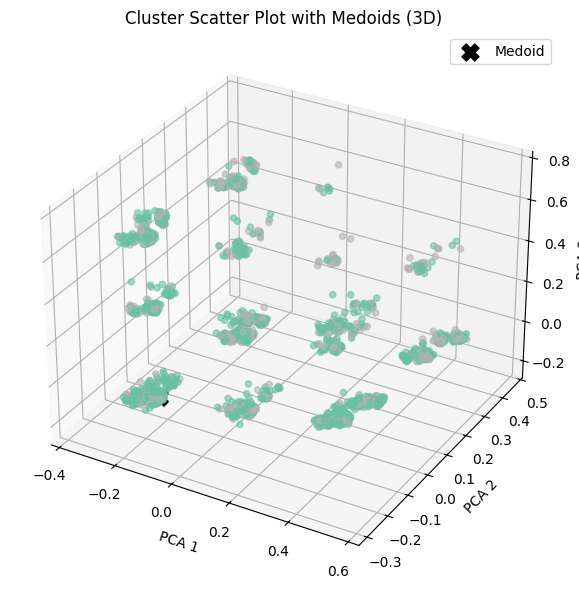

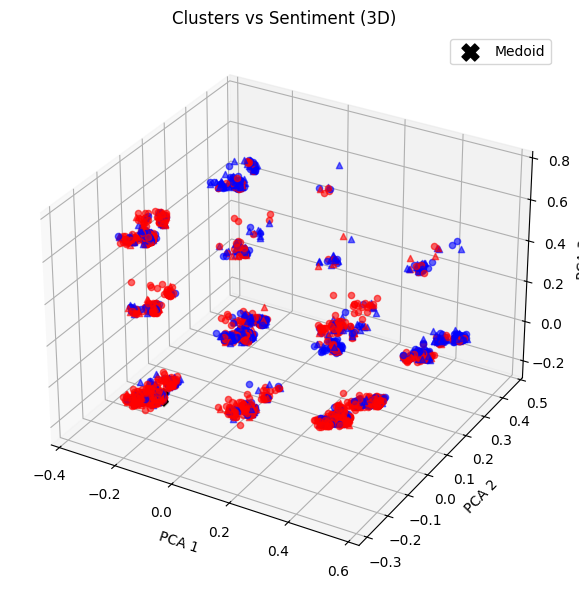

In [ ]:
from mpl_toolkits.mplot3d import Axes3D

# --- PCA for 3D plotting ---
pca = PCA(n_components=3)
X_3D = pca.fit_transform(X_ngrams)
X_medoids_3D = pca.transform(X_ngrams.iloc[medoid_indices])

# --- Plot 1: Clusters only (3D) ---
fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(111, projection='3d')
scatter = ax.scatter(X_3D[:, 0], X_3D[:, 1], X_3D[:, 2], c=labels, cmap='Set2', alpha=0.6)
ax.scatter(X_medoids_3D[:, 0], X_medoids_3D[:, 1], X_medoids_3D[:, 2],
           c='black', s=150, marker='X', label='Medoid')
ax.set_title("Cluster Scatter Plot with Medoids (3D)")
ax.set_xlabel("PCA 1")
ax.set_ylabel("PCA 2")
ax.set_zlabel("PCA 3")
plt.legend()
plt.tight_layout()
plt.show()

# --- Plot 2: Clusters vs Sentiment (3D) ---
fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(111, projection='3d')
sent_colors = df_eval['sentiment'].map({'positive': 'blue', 'negative': 'red'})
styles = df_eval['cluster'].map({0: 'o', 1: '^'})

for i in range(len(X_3D)):
    ax.scatter(X_3D[i, 0], X_3D[i, 1], X_3D[i, 2],
               c=sent_colors.iloc[i], marker=styles.iloc[i], alpha=0.6)

ax.scatter(X_medoids_3D[:, 0], X_medoids_3D[:, 1], X_medoids_3D[:, 2],
           c='black', s=150, marker='X', label='Medoid')
ax.set_title("Clusters vs Sentiment (3D)")
ax.set_xlabel("PCA 1")
ax.set_ylabel("PCA 2")
ax.set_zlabel("PCA 3")
plt.legend()
plt.tight_layout()
plt.show()


Numeric + N-gram features - euclidean distance

📈 Davies-Bouldin Index: 20.2716


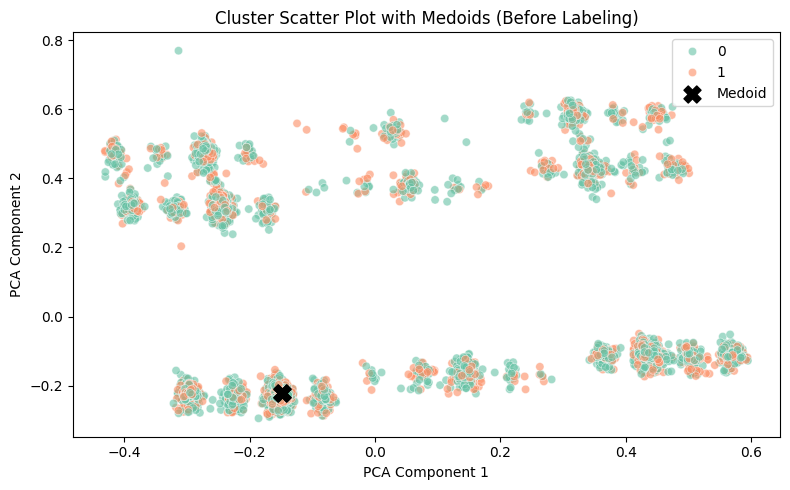

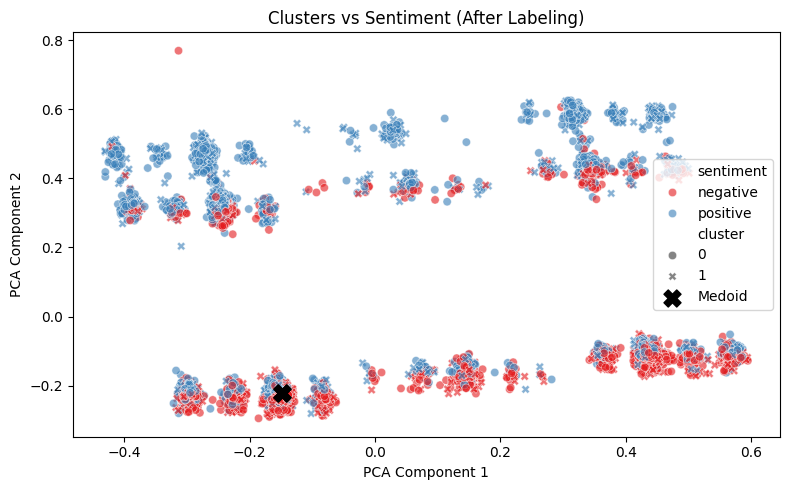

📊 Cluster vs Sentiment Table:
sentiment  negative  positive
cluster                      
0              3618      2784
1              2018      1580

🔍 Adjusted Rand Index (ARI): 0.0002
🔍 Normalized Mutual Information (NMI): 0.0000


In [ ]:
from sklearn_extra.cluster import KMedoids
from sklearn.metrics import davies_bouldin_score, adjusted_rand_score, normalized_mutual_info_score
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd

# featurs
metadata_features = [
    'pos_score_scaled', 'neg_score_scaled', 'followers_scaled',
    'previous_posts_count_scaled', 'hashtag_count_scaled'
]
ngram_cols = [col for col in df_model.columns if col.startswith('svd_')]

# sample
df_sampled = df_model.sample(n=10000, random_state=42)
X_meta = df_sampled[metadata_features]
X_ngrams = df_sampled[ngram_cols]

# merge
X_combined = pd.concat([X_meta.reset_index(drop=True), X_ngrams.reset_index(drop=True)], axis=1)

# --- K-Medoids with K = 2 ---
best_k = 2
kmedoids = KMedoids(n_clusters=best_k, metric='euclidean', random_state=42)
kmedoids.fit(X_combined)
labels = kmedoids.labels_
medoid_indices = kmedoids.medoid_indices_

# --- DBI ---
dbi = davies_bouldin_score(X_combined, labels)
print(f"📈 Davies-Bouldin Index: {dbi:.4f}")

# pce to 2-dim
pca = PCA(n_components=2)
X_2D = pca.fit_transform(X_combined)
X_medoids_2D = pca.transform(X_combined.iloc[medoid_indices])

# before labeling
plt.figure(figsize=(8, 5))
sns.scatterplot(x=X_2D[:, 0], y=X_2D[:, 1], hue=labels, palette='Set2', alpha=0.6)
plt.scatter(X_medoids_2D[:, 0], X_medoids_2D[:, 1],
            c='black', s=150, marker='X', label='Medoid')
plt.title("Cluster Scatter Plot with Medoids (Before Labeling)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.legend()
plt.tight_layout()
plt.show()

df_eval = df.loc[df_sampled.index].copy()
df_eval['cluster'] = labels

# after labaling
plt.figure(figsize=(8, 5))
sns.scatterplot(x=X_2D[:, 0], y=X_2D[:, 1],
                hue=df_eval['sentiment'],
                style=df_eval['cluster'],
                palette='Set1', alpha=0.6)
plt.scatter(X_medoids_2D[:, 0], X_medoids_2D[:, 1],
            c='black', s=150, marker='X', label='Medoid')
plt.title("Clusters vs Sentiment (After Labeling)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.legend()
plt.tight_layout()
plt.show()

# metrics
true_labels = df_eval['sentiment'].astype('category').cat.codes
ari = adjusted_rand_score(true_labels, labels)
nmi = normalized_mutual_info_score(true_labels, labels)

print("📊 Cluster vs Sentiment Table:")
print(pd.crosstab(df_eval['cluster'], df_eval['sentiment']))
print(f"\n🔍 Adjusted Rand Index (ARI): {ari:.4f}")
print(f"🔍 Normalized Mutual Information (NMI): {nmi:.4f}")


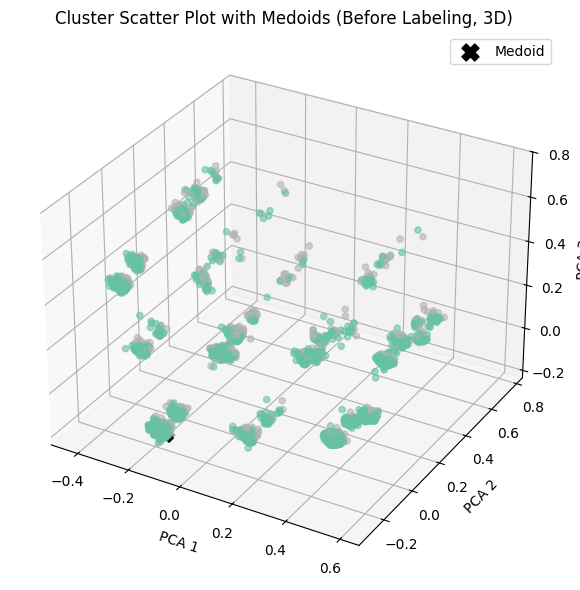

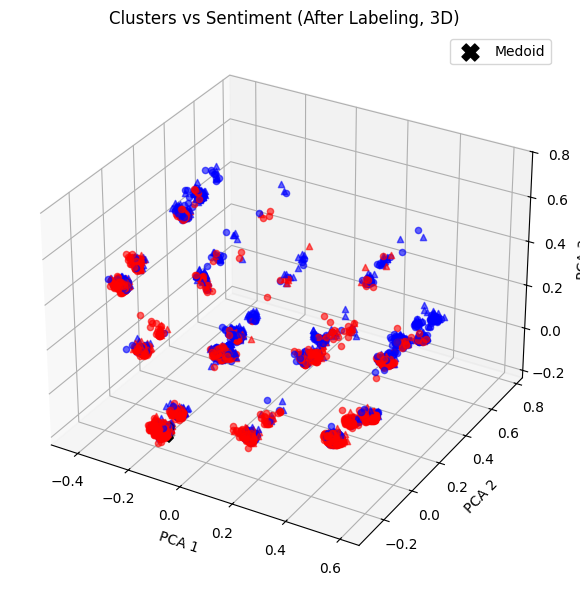

In [ ]:
from mpl_toolkits.mplot3d import Axes3D

# --- PCA to 3D ---
pca = PCA(n_components=3)
X_3D = pca.fit_transform(X_combined)
X_medoids_3D = pca.transform(X_combined.iloc[medoid_indices])

# --- Plot 1: Before Labeling (3D) ---
fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(111, projection='3d')
scatter = ax.scatter(X_3D[:, 0], X_3D[:, 1], X_3D[:, 2],
                     c=labels, cmap='Set2', alpha=0.6)
ax.scatter(X_medoids_3D[:, 0], X_medoids_3D[:, 1], X_medoids_3D[:, 2],
           c='black', s=150, marker='X', label='Medoid')
ax.set_title("Cluster Scatter Plot with Medoids (Before Labeling, 3D)")
ax.set_xlabel("PCA 1")
ax.set_ylabel("PCA 2")
ax.set_zlabel("PCA 3")
plt.legend()
plt.tight_layout()
plt.show()

# --- Plot 2: After Labeling (3D) ---
fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(111, projection='3d')
sent_colors = df_eval['sentiment'].map({'positive': 'blue', 'negative': 'red'})
styles = df_eval['cluster'].map({0: 'o', 1: '^'})

for i in range(len(X_3D)):
    ax.scatter(X_3D[i, 0], X_3D[i, 1], X_3D[i, 2],
               c=sent_colors.iloc[i], marker=styles.iloc[i], alpha=0.6)

ax.scatter(X_medoids_3D[:, 0], X_medoids_3D[:, 1], X_medoids_3D[:, 2],
           c='black', s=150, marker='X', label='Medoid')
ax.set_title("Clusters vs Sentiment (After Labeling, 3D)")
ax.set_xlabel("PCA 1")
ax.set_ylabel("PCA 2")
ax.set_zlabel("PCA 3")
plt.legend()
plt.tight_layout()
plt.show()
